# Memory experiment vs. LR-QAOA benchmark, campaign by campaign

On several days the same surface-code patches of `ibm_phoenix` were measured twice: by the **LR-QAOA
benchmark** (`benchmark_codes_ibm.ipynb`, the patch's checks as an Ising Hamiltonian, one syndrome-extraction
round per layer) and by the **memory experiment** (`benchmark_qec_memory.ipynb`, a logical qubit kept through
$R$ rounds and decoded), on the very same data qubits, ancillas and couplers, with a calibration snapshot of the
chip taken minutes before. This notebook puts every such **campaign** side by side and asks:

* how the chip evolves from one campaign to the next - in the benchmark, in the memory, in the calibration;
* whether each campaign ranks the patches the same way, and which patches stay good;
* how well the benchmark predicts the memory experiment, against every calibration number, campaign by campaign;
* which patches each method would pick, and how good those picks really were.

It only reads `data/`: no account, nothing is sent. A campaign harvested later appears on its own. Every
quantity is defined in the next section and computed in its cell.

In [2]:
import sys
from datetime import datetime
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))          # not needed after `pip install -e .`
DATA, FIGURES = ROOT / "data", ROOT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t as student_t

from qecbench.layout import square_lattice_coordinates

## 0. The quantities

A **campaign** is one day with both runs of `BACKEND` - the LR-QAOA benchmark
(`<stamp>_<backend>_surface_code_mcm.json`) and the memory experiment (`<stamp>_<backend>_surface_code_memory.json`)
- on the same patches, and a calibration snapshot taken just before. Per patch:

* **score** - the LR-QAOA $r_{\rm ovl}$ averaged over the depths $p \ge$ `MIN_DEPTH`, optionally only those with
  $r_{\rm ovl} >$ `R_OVL_FLOOR`. Used for the chip's history in section 3.
* **rank** - the patch's rank within its campaign at each of those depths, averaged (1 = best at every depth).
  Where a patch needs a single benchmark number this is the one used, because $r_{\rm ovl}$ falls steeply with
  depth - much more steeply in the X frame - so a plain mean is decided by the shallowest depth kept.
* $P_L^Z(R)$, $P_L^X(R)$ - the logical error rate measured after $R$ rounds, as decoded from the shots; where a
  patch needs one memory number, its $P_L$ after `R_REF` rounds (`mem_Z`, `mem_X`).
* **life** - the largest round count measured with $P_L$ below `PL_CEILING`, $Z$ and $X$ added.
* **calibration** - the mean and worst CZ error over the patch's couplers, the mean mid-circuit readout error of
  its ancillas, the mean final readout and `sx` error of its qubits, the mean $1/T_1$ and $1/T_2$ of its data
  qubits, and the **budget**: the unweighted sum of the errors of one round, every CZ, every ancilla readout and
  every data readout.

Every predictor is oriented so that larger means worse (the benchmark enters as $-$score), so a positive
Spearman $\rho$ against $P_L$ means it ranks the patches the way the memory experiment does.

In [3]:
import json
from dataclasses import dataclass, field
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np

from qecbench.analysis import instance_from_record, records_in

PREDICTORS = {                   # name: what it is (larger = worse for all of them)
    "rank": "LR-QAOA benchmark, Z frame: the patch's mean rank over depth (1 = best)",
    "rank_x": "the same benchmark in the X frame (when it was run)",
    "cz_mean": "mean CZ error over the patch's couplers",
    "cz_max": "worst CZ error of the patch",
    "anc_ro_mean": "mean mid-circuit readout error of the ancillas",
    "data_ro_mean": "mean final readout error of the data qubits",
    "sx_mean": "mean sx error of the patch's qubits",
    "inv_T1": "mean 1/T1 of the data qubits",
    "inv_T2": "mean 1/T2 of the data qubits",
    "budget": "sum of CZ, ancilla-readout and data-readout errors of one round",
}


# ======================================================================================
# Campaigns
# ======================================================================================
@dataclass
class Campaign:
    '''One day of both experiments on a backend.'''

    day: str                                  # "2026-09-22"
    lrqaoa: Path                              # the benchmark, Z frame (kind mcm)
    memory: Path
    calibration: Path | None = None           # snapshot file; None = the per-patch one inside the memory run
    calibration_age: timedelta | None = None  # how long before the memory run it was taken
    patches: list = field(default_factory=list)  # data-qubit tuples measured by every arm
    note: str = ""
    lrqaoa_x: Path | None = None              # the same benchmark in the X frame (kind mcm_x), when it was run

    @property
    def label(self):
        return self.day[5:]                   # "09-22"


def _created(path):
    '''When a run started: its header, else the ``YYYYMMDD_HHMM[SS]`` its file name starts with.'''
    doc = json.loads(Path(path).read_text())
    created = doc.get("run", {}).get("created")
    if created:
        return datetime.fromisoformat(created), doc
    stamp = "_".join(Path(path).name.split("_")[:2])
    return datetime.strptime(stamp, "%Y%m%d_%H%M%S" if len(stamp) == 15 else "%Y%m%d_%H%M"), doc


def _patches(doc):
    return {tuple(r["parameters"]["data_qubits"]) for r in records_in(doc)}


def discover(results_dir="data/results", backend="ibm_phoenix", calibration_dir="data/calibration",
             max_calibration_age_hours=6.0, min_patches=5):
    '''Every campaign of ``backend``: the LR-QAOA and memory runs of the same day, sharing their patches.

    A day whose benchmark also ran in the X frame (kind ``mcm_x``) carries it too, so both frames can be compared
    with both memories. Simulated runs are skipped. Of several runs on one day the latest of each kind is taken. The calibration is
    the latest snapshot fetched up to ``max_calibration_age_hours`` before the memory run started, else the
    per-patch snapshot the run stored itself, else none. A campaign with fewer than ``min_patches`` patches in
    common is still returned, with a ``note`` saying why it cannot be ranked.
    '''
    root = Path(results_dir) / backend / "surface_code"
    by_day = {}
    for kind in ("mcm", "mcm_x", "memory"):
        for path in sorted((root / kind).glob("*.json")):
            created, doc = _created(path)
            if doc["run"].get("simulated"):
                continue
            by_day.setdefault(created.date().isoformat(), {})[kind] = (created, path, doc)
    snapshots = []
    for path in sorted((Path(calibration_dir) / backend).glob("*_calibration.json")):
        fetched = json.loads(path.read_text()).get("fetched_at")
        if fetched:
            snapshots.append((datetime.fromisoformat(fetched), path))
    out = []
    for day, runs in sorted(by_day.items()):
        if not {"mcm", "memory"} <= set(runs):      # a day may also have the X frame
            continue
        (_, lrqaoa, doc_l), (started, memory, doc_m) = runs["mcm"], runs["memory"]
        lrqaoa_x = runs["mcm_x"][1] if "mcm_x" in runs else None
        common = sorted(_patches(doc_l) & _patches(doc_m)
                        & (_patches(runs["mcm_x"][2]) if lrqaoa_x else _patches(doc_m)))
        before = [(t, p) for t, p in snapshots if started - timedelta(hours=max_calibration_age_hours) <= t <= started]
        cal, age = (before[-1][1], started - before[-1][0]) if before else (None, None)
        if cal is None and not doc_m["run"].get("calibration"):
            note = "no calibration snapshot"
        else:
            note = ""
        if len(common) < min_patches:
            note = f"only {len(common)} patch(es) in both runs - not ranked"
        out.append(Campaign(day, lrqaoa, memory, cal, age, common, note, lrqaoa_x))
    return out


# ======================================================================================
# One row per patch and campaign
# ======================================================================================
def _coupler_error(cal, u, v):
    two = cal["two_qubit"]
    return (two.get(f"{u}-{v}") or two.get(f"{v}-{u}") or {}).get("error", np.nan)


def _qubit(cal, q):
    return cal["one_qubit"].get(str(q)) or {}


def calibration_of(patch, cal):
    '''The calibration predictors of ``patch`` from a device snapshot (``IBMBackend.calibration``).'''
    cz = np.array([_coupler_error(cal, u, v) for u, v in patch.couplers], float)
    data, anc = list(patch.data_qubits), list(patch.ancillas)
    ro_d = np.array([_qubit(cal, q).get("readout_error", np.nan) for q in data], float)
    ro_a = np.array([_qubit(cal, q).get("mcm_readout_error", np.nan) for q in anc], float)
    sx = np.array([_qubit(cal, q).get("sx_error", np.nan) for q in data + anc], float)
    t1 = np.array([_qubit(cal, q).get("T1", np.nan) for q in data], float)
    t2 = np.array([_qubit(cal, q).get("T2", np.nan) for q in data], float)
    return {"cz_mean": np.nanmean(cz), "cz_max": np.nanmax(cz), "anc_ro_mean": np.nanmean(ro_a),
            "data_ro_mean": np.nanmean(ro_d), "sx_mean": np.nanmean(sx),
            "inv_T1": float(np.nanmean(1 / t1)), "inv_T2": float(np.nanmean(1 / t2)),
            "budget": float(np.nansum(cz) + np.nansum(ro_a) + np.nansum(ro_d))}


def calibration_from_run(stored):
    '''The same predictors from the per-patch aggregates a position scan stored in its run header.'''
    return {"cz_mean": stored["cz_mean"], "cz_max": stored["cz_max"], "anc_ro_mean": stored["anc_mcm_ro_err_mean"],
            "data_ro_mean": stored["data_ro_err_mean"], "sx_mean": np.nan,
            "inv_T1": 1 / stored["data_T1_mean"], "inv_T2": 1 / stored["data_T2_mean"],
            "budget": stored["cz_sum"] + stored["anc_mcm_ro_err_sum"] + stored["data_ro_err_sum"]}


def patch_rows(campaigns, distance=3, min_depth=2, r_ovl_floor=None, pl_ceiling=0.10, r_ref=3):
    '''One dict per (campaign, patch) of ``distance``, with every number of the module docstring.'''
    rows = []
    for camp in campaigns:
        doc_l = json.loads(camp.lrqaoa.read_text())
        doc_x = json.loads(camp.lrqaoa_x.read_text()) if camp.lrqaoa_x else None
        doc_m = json.loads(camp.memory.read_text())
        snapshot = json.loads(camp.calibration.read_text()) if camp.calibration else None
        stored = doc_m["run"].get("calibration") or {}
        keep = set(camp.patches)
        depths, depths_x, patch_of = {}, {}, {}
        for doc, into in ((doc_l, depths), (doc_x, depths_x)):
            for rec in records_in(doc) if doc else ():
                key = tuple(rec["parameters"]["data_qubits"])
                if key in keep:
                    into.setdefault(key, {})[rec["parameters"]["depth"]] = rec["benchmark"]["r_ovl"]
        rates = {}
        for rec in records_in(doc_m):
            key = tuple(rec["parameters"]["data_qubits"])
            if key in keep:
                patch_of.setdefault(key, instance_from_record(rec))
                b, p = rec["benchmark"], rec["parameters"]
                rates.setdefault(key, {}).setdefault(p["basis"], {})[p["rounds"]] = b["logical_error_rate"]
        for key in camp.patches:
            patch = patch_of.get(key)
            if patch is None or patch.code.info.get("distance") != distance:
                continue
            kept = lambda by: {p: v for p, v in sorted(by.items())
                               if p >= min_depth and (r_ovl_floor is None or v > r_ovl_floor)}
            used, used_x = kept(depths.get(key, {})), kept(depths_x.get(key, {}))
            row = {"day": camp.day, "campaign": camp.label, "patch": key, "name": f"@{min(key)}",
                   "r_ovl": dict(sorted(depths.get(key, {}).items())), "depths_used": list(used),
                   "r_ovl_x": dict(sorted(depths_x.get(key, {}).items())),
                   "score": float(np.mean(list(used.values()))) if used else np.nan,
                   "score_x": float(np.mean(list(used_x.values()))) if used_x else np.nan}
            for basis, series in rates.get(key, {}).items():
                below = [r for r in sorted(series) if series[r] < pl_ceiling]
                row.update({f"P_L_{basis}": dict(sorted(series.items())), f"mem_{basis}": series.get(r_ref, np.nan),
                            f"life_{basis}": max(below) if below else 0})
            row["life"] = row.get("life_Z", 0) + row.get("life_X", 0)
            row["-life"] = -row["life"]                   # larger = worse, like every other target
            if snapshot is not None:
                row.update(calibration_of(patch, snapshot))
            else:
                name = next((k for k, v in stored.items() if sorted(v["data_qubits"]) == sorted(key)), None)
                row.update(calibration_from_run(stored[name]) if name else {k: np.nan for k in PREDICTORS if k != "-score"})
            row["-score"], row["-score_x"] = -row["score"], -row["score_x"]
            rows.append(row)
    return rows


# ======================================================================================
# Comparisons
# ======================================================================================
def spearman(x, y):
    '''``(rho, p, n)`` over the finite pairs; NaN below three of them.'''
    from scipy.stats import spearmanr

    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 3 or np.ptp(x[ok]) == 0 or np.ptp(y[ok]) == 0:
        return np.nan, np.nan, int(ok.sum())
    r, p = spearmanr(x[ok], y[ok])
    return float(r), float(p), int(ok.sum())


def by_campaign(rows):
    out = {}
    for row in rows:
        out.setdefault(row["campaign"], []).append(row)
    return out


def agreement(rows, predictor, target):
    '''``{campaign: (rho, p, n)}`` and ``"pooled"``: how ``predictor`` ranks the patches against ``target``.'''
    out = {c: spearman([r[predictor] for r in sub], [r[target] for r in sub]) for c, sub in by_campaign(rows).items()}
    out["pooled"] = spearman([r[predictor] for r in rows], [r[target] for r in rows])
    return out


def stability(rows, metric):
    '''``{(a, b): (rho, p, n)}``: does ``metric`` rank the same patches the same way in campaigns ``a`` and ``b``?'''
    camps = by_campaign(rows)
    names = sorted(camps)
    out = {}
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            va = {r["patch"]: r[metric] for r in camps[a]}
            vb = {r["patch"]: r[metric] for r in camps[b]}
            common = sorted(set(va) & set(vb))
            out[(a, b)] = spearman([va[k] for k in common], [vb[k] for k in common])
    return out


def pick(rows, predictor, k=3):
    '''The ``k`` rows with the smallest ``predictor`` (every predictor is larger = worse).'''
    ok = [r for r in rows if np.isfinite(r[predictor])]
    return sorted(ok, key=lambda r: r[predictor])[:k]


def selection(rows, predictor, outcome="life", k=3):
    '''``{campaign: (chosen, typical, best possible)}``: mean ``outcome`` of the ``k`` patches ``predictor`` picks,
    of every patch, and of the ``k`` best there were (larger ``outcome`` = better, e.g. rounds under the ceiling).'''
    out = {}
    for c, sub in by_campaign(rows).items():
        values = [r[outcome] for r in sub if np.isfinite(r[outcome])]
        chosen = [r[outcome] for r in pick(sub, predictor, k)]
        out[c] = (float(np.nanmean(chosen)), float(np.mean(values)), float(np.mean(sorted(values)[-k:])))
    return out


def chip_graph(calibration_path):
    '''The coupling graph of the chip, from the couplers a calibration snapshot lists.'''
    import networkx as nx

    cal = json.loads(Path(calibration_path).read_text())
    G = nx.Graph()
    G.add_nodes_from(int(q) for q in cal["one_qubit"])
    G.add_edges_from(tuple(int(q) for q in key.split("-")) for key in cal["two_qubit"])
    return G

## 1. Configuration - the only cell you normally edit

* `BACKEND` - the chip. `DISTANCE` - the patches compared.
* `MIN_DEPTH`, `R_OVL_FLOOR` - which LR-QAOA depths make up a patch's **score** (the mean $r_{\rm ovl}$): every
  $p \ge$ `MIN_DEPTH` with $r_{\rm ovl} >$ `R_OVL_FLOOR` (`None`: no floor). `MIN_DEPTH = 2` leaves out the
  one-layer circuit, which barely tells patches apart.
* `PL_CEILING` - the logical error rate below which a memory result counts: a patch's **lifetime** is the largest
  number of rounds it stays under it, per basis.
* `R_REF` - the round count whose $P_L$ stands for a patch where one memory number is needed (sections 3, 4, 6).
* `TOP` - how many patches a method picks. `OUTCOME` - what a pick is judged by: `"life"` (rounds under the
  ceiling, $Z$ + $X$), `"life_Z"` or `"life_X"`.
* `EXCLUDE` - campaign days to leave out, e.g. `["2026-09-17"]`.

In [4]:
BACKEND     = "ibm_phoenix"
DISTANCE    = 3
MIN_DEPTH   = 1          # 2 leaves out the one-layer circuit
R_OVL_FLOOR = 0.1        # None: every depth from MIN_DEPTH
PL_CEILING  = 0.10
R_REF       = 3          # the P_L that stands for a patch where one memory number is needed
TOP         = 3
OUTCOME     = "life"     # "life", "life_Z" or "life_X"
EXCLUDE     = []

## 2. The campaigns

Each day with both a (non-simulated) LR-QAOA run and a memory run of `BACKEND`, the patches the two share, and
the calibration snapshot: the latest one taken up to six hours before the memory run started, or the per-patch
snapshot the run stored itself (the 2026-09-14 position scan). A campaign with too few patches in common is
listed but not ranked.

In [5]:
found = [c for c in discover(DATA / "results", BACKEND, DATA / "calibration") if c.day not in EXCLUDE]
print(f"{'day':>10}  {'LR-QAOA run (Z frame)':>46}  {'X frame':>9}  {'memory run':>52}  {'cal age':>8} {'patches':>8}")
for c in found:
    age = "" if c.calibration_age is None else f"{c.calibration_age.total_seconds() / 60:.0f} min"
    print(f"{c.day:>10}  {c.lrqaoa.name:>46}  {('yes' if c.lrqaoa_x else '-'):>9}  {c.memory.name:>52}  "
          f"{age:>8} {len(c.patches):>8}" + (f"   <- {c.note}" if c.note else ""))
campaigns = [c for c in found if not c.note.startswith("only")]
rows = patch_rows(campaigns, distance=DISTANCE, min_depth=MIN_DEPTH, r_ovl_floor=R_OVL_FLOOR,
                     pl_ceiling=PL_CEILING, r_ref=R_REF)
per = by_campaign(rows)
labels = sorted(per)
days = {c.label: datetime.fromisoformat(c.day) for c in campaigns}
for _c, _sub in by_campaign(rows).items():          # depth-averaged rank, per frame
    for _key, _frame in (("rank", "r_ovl"), ("rank_x", "r_ovl_x")):
        _depths = sorted(set.intersection(*(set(r[_frame]) for r in _sub))) if all(r[_frame] for r in _sub) else []
        _depths = [p for p in _depths if p >= MIN_DEPTH]
        for r in _sub:
            r[_key] = float(np.mean([sorted(_sub, key=lambda q: -q[_frame][p]).index(r) + 1 for p in _depths])) \
                if _depths else np.nan

names = sorted({r["name"] for r in rows}, key=lambda n: int(n[1:]))
with_x = [c.label for c in campaigns if c.lrqaoa_x]
print(f"\n{len(labels)} campaigns ranked, {len(names)} surface_d{DISTANCE} patches: {', '.join(names)}")
print(f"both frames of the benchmark: {', '.join(with_x) if with_x else 'none yet'}")

       day                           LR-QAOA run (Z frame)    X frame                                            memory run   cal age  patches
2026-09-14  20260914_0941_ibm_phoenix_surface_code_mcm.json          -    20260914_0941_ibm_phoenix_surface_code_memory.json                 19
2026-09-17  20260917_140334_ibm_phoenix_surface_code_mcm.json          -  20260917_155616_ibm_phoenix_surface_code_memory.json     0 min        4   <- only 4 patch(es) in both runs - not ranked
2026-09-18  20260918_134642_ibm_phoenix_surface_code_mcm.json          -  20260918_122404_ibm_phoenix_surface_code_memory.json     1 min       19
2026-09-21  20260921_084439_ibm_phoenix_surface_code_mcm.json          -  20260921_084348_ibm_phoenix_surface_code_memory.json     0 min       19
2026-09-22  20260922_132637_ibm_phoenix_surface_code_mcm.json        yes  20260922_152938_ibm_phoenix_surface_code_memory.json     0 min       19
2026-09-23  20260923_163523_ibm_phoenix_surface_code_mcm.json        yes  2026092

## 3. The chip over time

Every patch is a faint line; the thick line is the median over the patches and the band their inter-quartile
range. Top row: the two experiments - the benchmark score (higher is better) and the logical error per round in
each basis (lower is better). Bottom row: the calibration of the same patches.

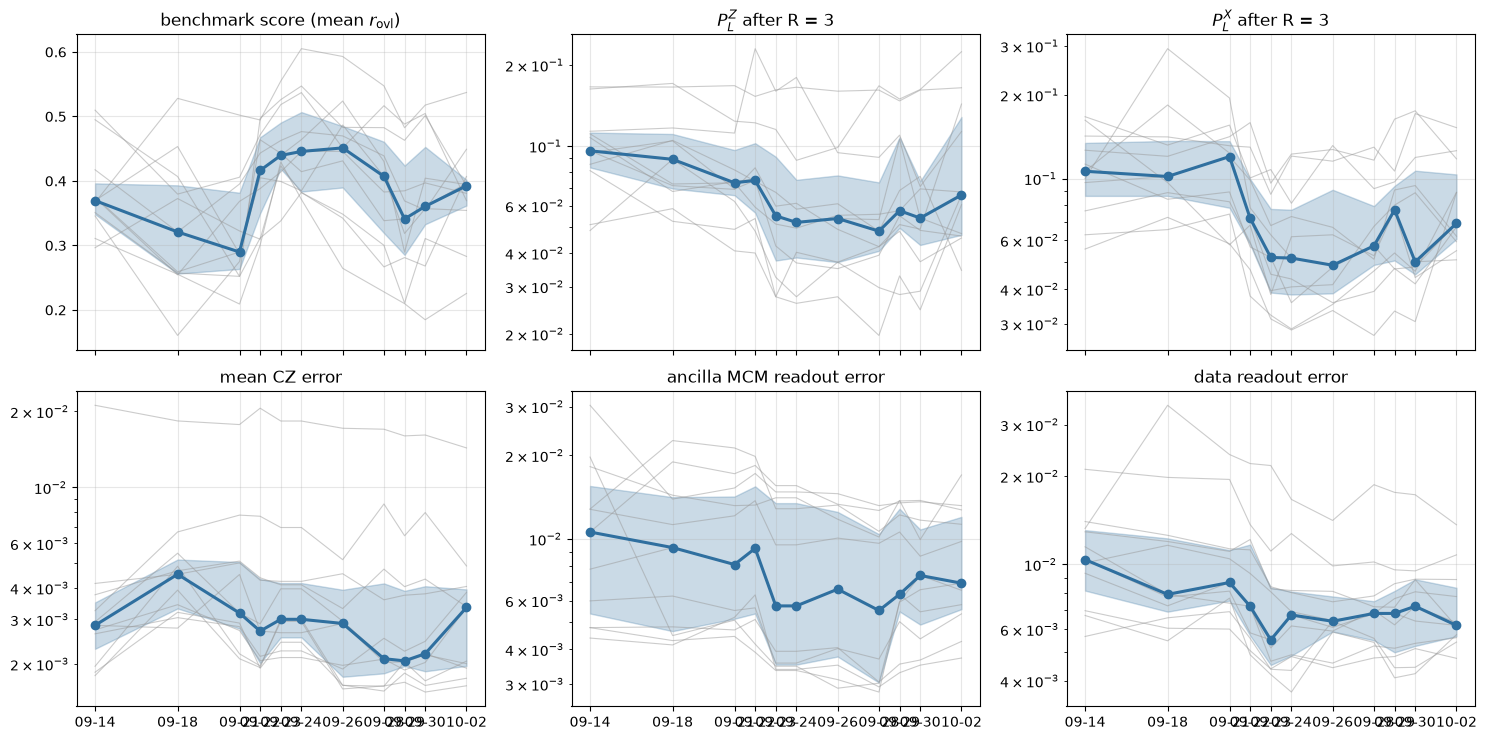

 campaign    benchmark score      P_L^Z at R=3      P_L^X at R=3     mean CZ error   ancilla readout      data readout
    09-14             0.3696            0.0960            0.1062            0.0028            0.0106            0.0104
    09-18             0.3209            0.0892            0.1017            0.0045            0.0093            0.0079
    09-21             0.2898            0.0730            0.1200            0.0032            0.0081            0.0087
    09-22             0.4163            0.0745            0.0720            0.0027            0.0092            0.0072
    09-23             0.4396            0.0550            0.0520            0.0030            0.0057            0.0055
    09-24             0.4458            0.0520            0.0517            0.0030            0.0057            0.0067
    09-26             0.4513            0.0537            0.0488            0.0029            0.0066            0.0064
    09-28             0.4071            0.0483  

In [6]:
panels = [("score", r"benchmark score (mean $r_{\rm ovl}$)", False), ("mem_Z", rf"$P_L^Z$ after R = {R_REF}", True),
          ("mem_X", rf"$P_L^X$ after R = {R_REF}", True), ("cz_mean", "mean CZ error", True),
          ("anc_ro_mean", "ancilla MCM readout error", True), ("data_ro_mean", "data readout error", True)]
PLAIN = {"score": "benchmark score", "mem_Z": f"P_L^Z at R={R_REF}", "mem_X": f"P_L^X at R={R_REF}",
         "cz_mean": "mean CZ error", "anc_ro_mean": "ancilla readout", "data_ro_mean": "data readout"}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
x = [days[c] for c in labels]
for ax, (metric, title, log) in zip(axes.flat, panels):
    for name in names:
        series = [next((r[metric] for r in per[c] if r["name"] == name), np.nan) for c in labels]
        ax.plot(x, series, "-", color="0.6", lw=0.8, alpha=0.5)
    values = [np.array([r[metric] for r in per[c]], float) for c in labels]
    med = [np.nanmedian(v) for v in values]
    ax.fill_between(x, [np.nanpercentile(v, 25) for v in values], [np.nanpercentile(v, 75) for v in values],
                    color="#2f6f9f", alpha=0.25)
    ax.plot(x, med, "o-", color="#2f6f9f", lw=2.2)
    ax.set(title=title, yscale="log" if log else "linear")
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xticks(x, labels)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_evolution.pdf", bbox_inches="tight")
plt.show()

print(f"{'campaign':>9} " + "".join(f"{PLAIN[m]:>18}" for m, _, _ in panels))
for c in labels:
    print(f"{c:>9} " + "".join(f"{np.nanmedian([r[m] for r in per[c]]):>18.4f}" for m, _, _ in panels))

## 4. Patch by patch: does the ranking hold from one campaign to the next?

Each patch's **rank** in every campaign (1 = best), by the benchmark, by each basis of the memory experiment and by
the CZ error. A patch that is good for the chip stays near the top of its column; noise in a measurement shuffles
it. Below, the Spearman correlation of the ranking between every pair of campaigns: how reproducible each
measurement is on its own, before it is compared with anything else.

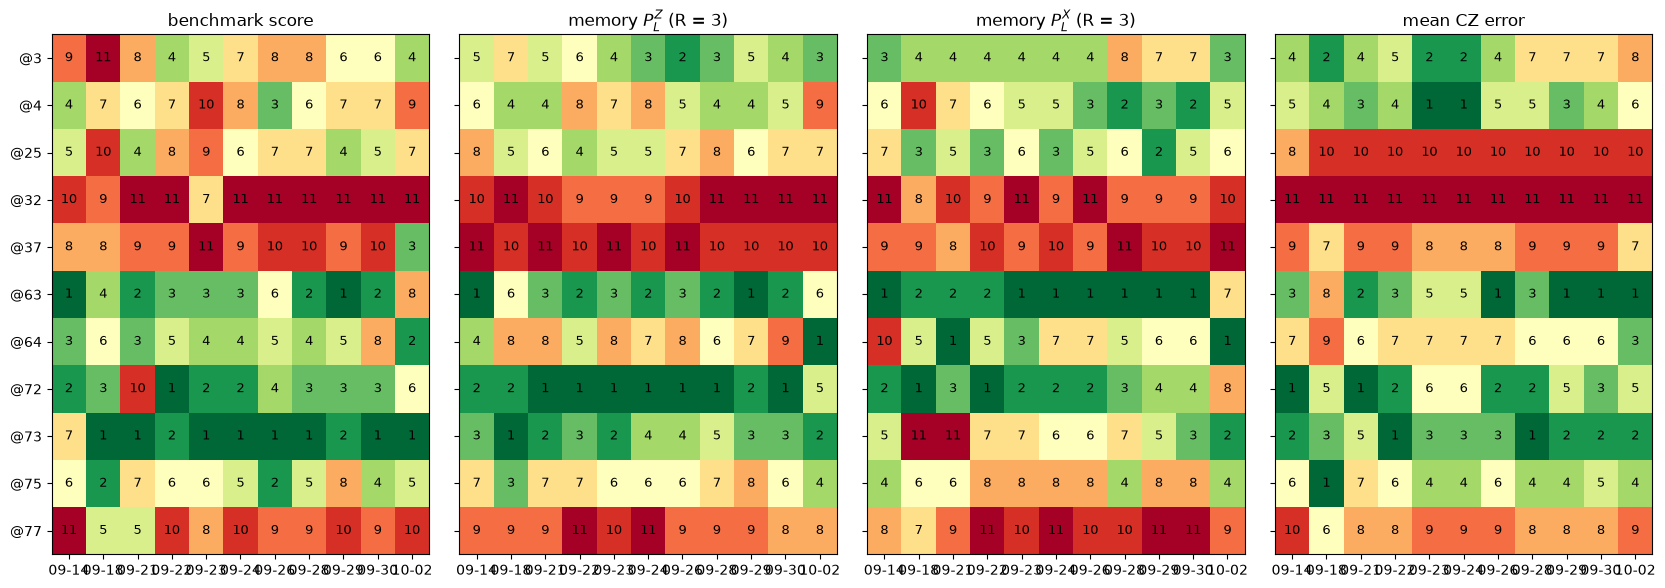

ranking stability, Spearman rho between campaigns (p in brackets):
   benchmark score: 09-14/09-18 +0.34 (0.31)  09-14/09-21 +0.34 (0.31)  09-14/09-22 +0.64 (0.04)  09-14/09-23 +0.38 (0.25)  09-14/09-24 +0.70 (0.02)  09-14/09-26 +0.55 (0.08)  09-14/09-28 +0.74 (0.01)  09-14/09-29 +0.75 (0.01)  09-14/09-30 +0.57 (0.07)  09-14/10-02 +0.16 (0.63)  09-18/09-21 +0.37 (0.26)  09-18/09-22 +0.52 (0.10)  09-18/09-23 +0.59 (0.06)  09-18/09-24 +0.65 (0.03)  09-18/09-26 +0.71 (0.01)  09-18/09-28 +0.73 (0.01)  09-18/09-29 +0.37 (0.26)  09-18/09-30 +0.61 (0.05)  09-18/10-02 +0.25 (0.47)  09-21/09-22 +0.34 (0.31)  09-21/09-23 +0.34 (0.31)  09-21/09-24 +0.53 (0.10)  09-21/09-26 +0.47 (0.14)  09-21/09-28 +0.64 (0.04)  09-21/09-29 +0.61 (0.05)  09-21/09-30 +0.52 (0.10)  09-21/10-02 +0.31 (0.36)  09-22/09-23 +0.83 (0.00)  09-22/09-24 +0.92 (0.00)  09-22/09-26 +0.68 (0.02)  09-22/09-28 +0.87 (0.00)  09-22/09-29 +0.85 (0.00)  09-22/09-30 +0.85 (0.00)  09-22/10-02 +0.54 (0.09)  09-23/09-24 +0.81 (0.00)  09-

In [7]:
def ranks(metric, better_high=False):
    out = np.full((len(names), len(labels)), np.nan)
    for j, c in enumerate(labels):
        sub = [r for r in per[c] if np.isfinite(r[metric])]
        order = sorted(sub, key=lambda r: -r[metric] if better_high else r[metric])
        for k, r in enumerate(order):
            out[names.index(r["name"]), j] = k + 1
    return out

rank_panels = [("score", "benchmark score", True), ("mem_Z", rf"memory $P_L^Z$ (R = {R_REF})", False),
               ("mem_X", rf"memory $P_L^X$ (R = {R_REF})", False), ("cz_mean", "mean CZ error", False)]
fig, axes = plt.subplots(1, len(rank_panels), figsize=(4.2 * len(rank_panels), 0.38 * len(names) + 1.8), sharey=True)
for ax, (metric, title, high) in zip(axes, rank_panels):
    R = ranks(metric, high)
    ax.imshow(R, cmap="RdYlGn_r", vmin=1, vmax=len(names), aspect="auto")
    for i in range(len(names)):
        for j in range(len(labels)):
            if np.isfinite(R[i, j]):
                ax.text(j, i, f"{R[i, j]:.0f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(title)
axes[0].set_yticks(range(len(names)), names)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_ranks.pdf", bbox_inches="tight")
plt.show()

print("ranking stability, Spearman rho between campaigns (p in brackets):")
for metric, title, _ in rank_panels:
    pairs = stability(rows, metric)
    print(f"  {PLAIN[metric]:>16}: " + "  ".join(f"{a}/{b} {v[0]:+.2f} ({v[1]:.2f})" for (a, b), v in pairs.items()))

## 5. Depth by depth: $r_{\rm ovl}$ at $p$ against $P_L$ after $R = p$ rounds

The finest comparison the two experiments allow. One LR-QAOA layer is one syndrome-extraction round, and both
were run at the same depths, so every patch gives a directly paired point at each $p = R$: its $r_{\rm ovl}$
after $p$ layers and its measured logical error rate after $R = p$ rounds, with no average over depths. For
each campaign and depth, $\rho$ ranks the patches by $-r_{\rm ovl}(p)$ against $P_L(R)$ (positive = the patch
the benchmark rates higher keeps its logical qubit better at that depth). **Pooled** ranks the patches within
each campaign first, so a chip-wide shift from one day to the next cannot count as agreement.

Where the benchmark ran in **both frames**, each is compared with **both memories**: the Z frame ($Z\cdots Z$
checks, data from $|+\rangle$, read in $Z$) and the X frame (the same algorithm conjugated by $H$ on every data
qubit), against $P_L^Z$ and $P_L^X$. If the frame is what decides, each frame agrees best with the memory of its
own basis.

The second table keeps only the points inside the cuts of the configuration cell ($r_{\rm ovl} >$ `R_OVL_FLOOR`
and $P_L <$ `PL_CEILING`); $n$ shows how many patches are left. Below: the same $\rho$ for the calibration
numbers, which do not change with $R$ but are compared with $P_L$ at each $R$ in the same way.


memory Z: rho(-r_ovl(p), P_L^Z(R = p))   every point
 campaign   frame       p = R = 3
    09-14       Z    +0.84 (n=11)
    09-18       Z    +0.34 (n=11)
    09-21       Z    +0.45 (n=11)
    09-22       Z    +0.80 (n=11)
    09-22       X    +0.81 (n=11)
    09-23       Z    +0.84 (n=11)
    09-23       X    +0.70 (n=11)
    09-24       Z    +0.80 (n=11)
    09-24       X    +0.87 (n=11)
    09-26       Z    +0.77 (n=11)
    09-26       X    +0.79 (n=11)
    09-28       Z    +0.76 (n=11)
    09-28       X    +0.88 (n=11)
    09-29       Z    +0.90 (n=11)
    09-29       X    +0.76 (n=11)
    09-30       Z    +0.88 (n=11)
    09-30       X    +0.72 (n=11)
    10-02       Z    +0.73 (n=11)
    10-02       X    +0.75 (n=11)
   pooled       Z   +0.74 (n=121)
   pooled       X    +0.79 (n=88)

memory Z: rho(-r_ovl(p), P_L^Z(R = p))   only r_ovl > 0.1 and P_L < 10%
 campaign   frame       p = R = 3
    09-14       Z    +0.94 (n= 6)
    09-18       Z    +0.54 (n= 6)
    09-21       Z    +0

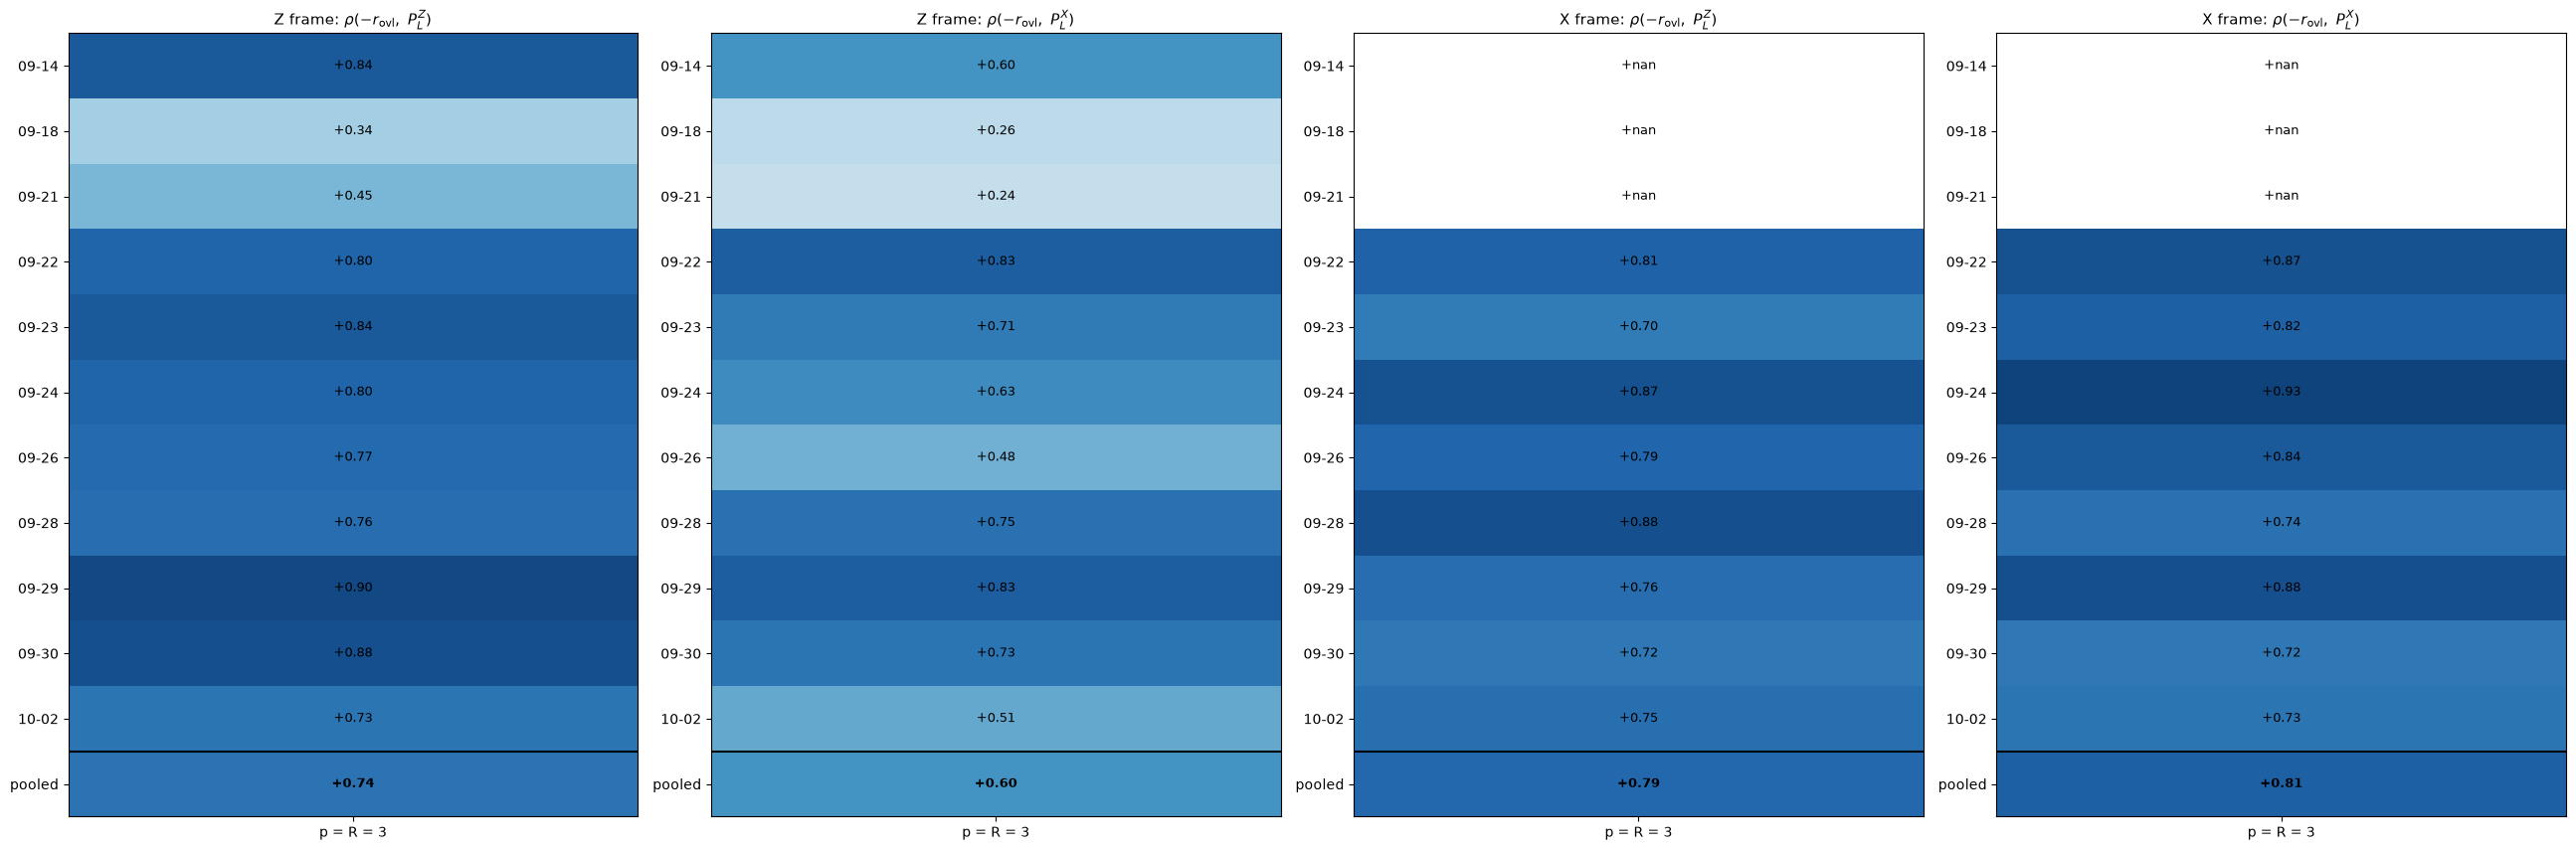

In [8]:
from scipy.stats import rankdata

P = sorted(set.intersection(*(set(r["r_ovl"]) & set(r["P_L_Z"]) & set(r["P_L_X"]) for r in rows)))

def depth_pairs(sub, p, basis, predictor="r_ovl", cut=False):
    xs, ys = [], []
    for r in sub:
        key = predictor if predictor.startswith("r_ovl") else "r_ovl"
        ro, pl = r.get(key, {}).get(p, np.nan), r[f"P_L_{basis}"].get(p, np.nan)
        if cut and not ((R_OVL_FLOOR is None or ro > R_OVL_FLOOR) and pl < PL_CEILING):
            continue
        xs.append(-ro if predictor.startswith("r_ovl") else r[predictor])
        ys.append(pl)
    return xs, ys

def depth_rho(p, basis, predictor="r_ovl", cut=False, campaign=None):
    if campaign is not None:
        return spearman(*depth_pairs(per[campaign], p, basis, predictor, cut))
    xs, ys = [], []                               # pooled: ranks within each campaign
    for c in labels:
        x, y = depth_pairs(per[c], p, basis, predictor, cut)
        if len(x) >= 3:
            xs += list(rankdata(x) / len(x))
            ys += list(rankdata(y) / len(y))
    return spearman(xs, ys)

BENCH = {"Z frame": "r_ovl"}
if any(r["r_ovl_x"] for r in rows):
    BENCH["X frame"] = "r_ovl_x"
for basis in ("Z", "X"):
    for cut in (False, True):
        print(f"\nmemory {basis}: rho(-r_ovl(p), P_L^{basis}(R = p))" +
              (f"   only r_ovl > {R_OVL_FLOOR} and P_L < {PL_CEILING:.0%}" if cut else "   every point"))
        print(f"{'campaign':>9} {'frame':>7} " + "".join(f"{'p = R = ' + str(p):>15}" for p in P))
        for c in labels + ["pooled"]:
            for frame, pred in BENCH.items():
                cells = [depth_rho(p, basis, predictor=pred, cut=cut, campaign=None if c == "pooled" else c)
                         for p in P]
                if all(not np.isfinite(v[0]) for v in cells):
                    continue
                print(f"{c:>9} {frame.split()[0]:>7} "
                      + "".join((f"{v[0]:+.2f} (n={v[2]:>2})" if np.isfinite(v[0]) else f"   -   (n={v[2]:>2})").rjust(15)
                                for v in cells))

heat_panels = [(frame, pred, basis) for frame, pred in BENCH.items() for basis in ("Z", "X")]
fig, axes = plt.subplots(1, len(heat_panels), figsize=(6.5 * len(heat_panels), 0.55 * len(labels) + 2.6),
                         squeeze=False)
for ax, (frame, pred, basis) in zip(axes[0], heat_panels):
    M = np.array([[depth_rho(p, basis, predictor=pred, campaign=None if c == "pooled" else c)[0] for p in P]
                  for c in labels + ["pooled"]])
    ax.imshow(M, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:+.2f}", ha="center", va="center", fontsize=9,
                    fontweight="bold" if i == M.shape[0] - 1 else "normal")
    ax.axhline(len(labels) - 0.5, color="k", lw=1.5)
    ax.set_xticks(range(len(P)), [f"p = R = {p}" for p in P])
    ax.set_yticks(range(len(labels) + 1), labels + ["pooled"])
    ax.set_title(rf"{frame}: $\rho(-r_{{\rm ovl}},\ P_L^{{{basis}}})$", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_depth_rho.pdf", bbox_inches="tight")
plt.show()

### Every patch at every depth

One panel per depth and basis: each patch of each campaign as a point, its $r_{\rm ovl}$ after $p$ layers against
its logical error rate after $R = p$ rounds, coloured by campaign. The grey band is the `PL_CEILING` cut.

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

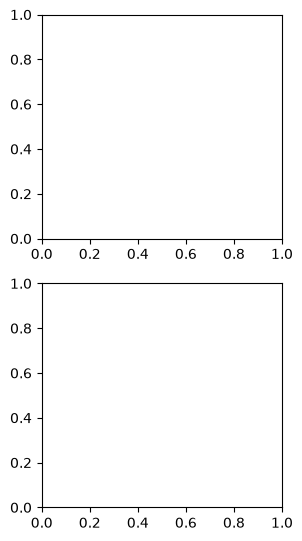

In [9]:
colours = {c: plt.get_cmap("viridis")(k / max(len(labels) - 1, 1)) for k, c in enumerate(labels)}
fig, axes = plt.subplots(2, len(P), figsize=(3.1 * len(P), 6.4), sharey="row")
for i, basis in enumerate(("Z", "X")):
    for j, p in enumerate(P):
        ax = axes[i, j]
        for c in labels:
            ro = [r["r_ovl"].get(p, np.nan) for r in per[c]]
            pl = [r[f"P_L_{basis}"].get(p, np.nan) for r in per[c]]
            ax.scatter(ro, pl, s=22, color=colours[c], label=c if (i, j) == (0, 0) else None)
        ax.axhspan(1e-3, PL_CEILING, color="0.85", zorder=0)
        ax.set_yscale("log")
        ax.grid(alpha=0.3)
        rho = depth_rho(p, basis)[0]
        ax.set_title(f"p = R = {p}   pooled $\\rho$ = {rho:+.2f}", fontsize=9)
        if i == 1:
            ax.set_xlabel(r"$r_{\rm ovl}(p)$")
    axes[i, 0].set_ylabel(rf"$P_L^{basis}(R)$")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_depth_scatter.pdf", bbox_inches="tight")
plt.show()

### The two frames against each other

Every patch of every campaign that ran both frames, at every depth: $r_{\rm ovl}$ in the Z frame against
$r_{\rm ovl}$ in the X frame, coloured by depth, with the diagonal for reference. Noiselessly the two frames give
the same $r$, so every point would sit on the diagonal; on the device the distance below it is the extra error the
X frame sees - the phase-type noise the data pick up while the ancillas are read. The spread along each depth's
cloud is what the two frames disagree about when ranking patches.

09-22  p =  1: mean r_ovl  Z 0.690  X 0.777  X - Z +0.087   rho(Z, X) = -0.10
09-22  p =  2: mean r_ovl  Z 0.460  X 0.464  X - Z +0.004   rho(Z, X) = +0.71
09-22  p =  3: mean r_ovl  Z 0.378  X 0.320  X - Z -0.058   rho(Z, X) = +0.85
09-22  p =  5: mean r_ovl  Z 0.326  X 0.198  X - Z -0.127   rho(Z, X) = +0.83
09-22  p =  7: mean r_ovl  Z 0.325  X 0.143  X - Z -0.181   rho(Z, X) = +0.74
09-22  p = 10: mean r_ovl  Z 0.239  X 0.082  X - Z -0.157   rho(Z, X) = +0.64
09-23  p =  1: mean r_ovl  Z 0.772  X 0.786  X - Z +0.014   rho(Z, X) = +0.16
09-23  p =  2: mean r_ovl  Z 0.511  X 0.501  X - Z -0.009   rho(Z, X) = +0.75
09-23  p =  3: mean r_ovl  Z 0.393  X 0.334  X - Z -0.059   rho(Z, X) = +0.79
09-23  p =  5: mean r_ovl  Z 0.359  X 0.213  X - Z -0.146   rho(Z, X) = +0.61
09-23  p =  7: mean r_ovl  Z 0.362  X 0.148  X - Z -0.214   rho(Z, X) = +0.80
09-23  p = 10: mean r_ovl  Z 0.271  X 0.076  X - Z -0.195   rho(Z, X) = +0.62
09-24  p =  1: mean r_ovl  Z 0.735  X 0.773  X - Z +0.038   rho(

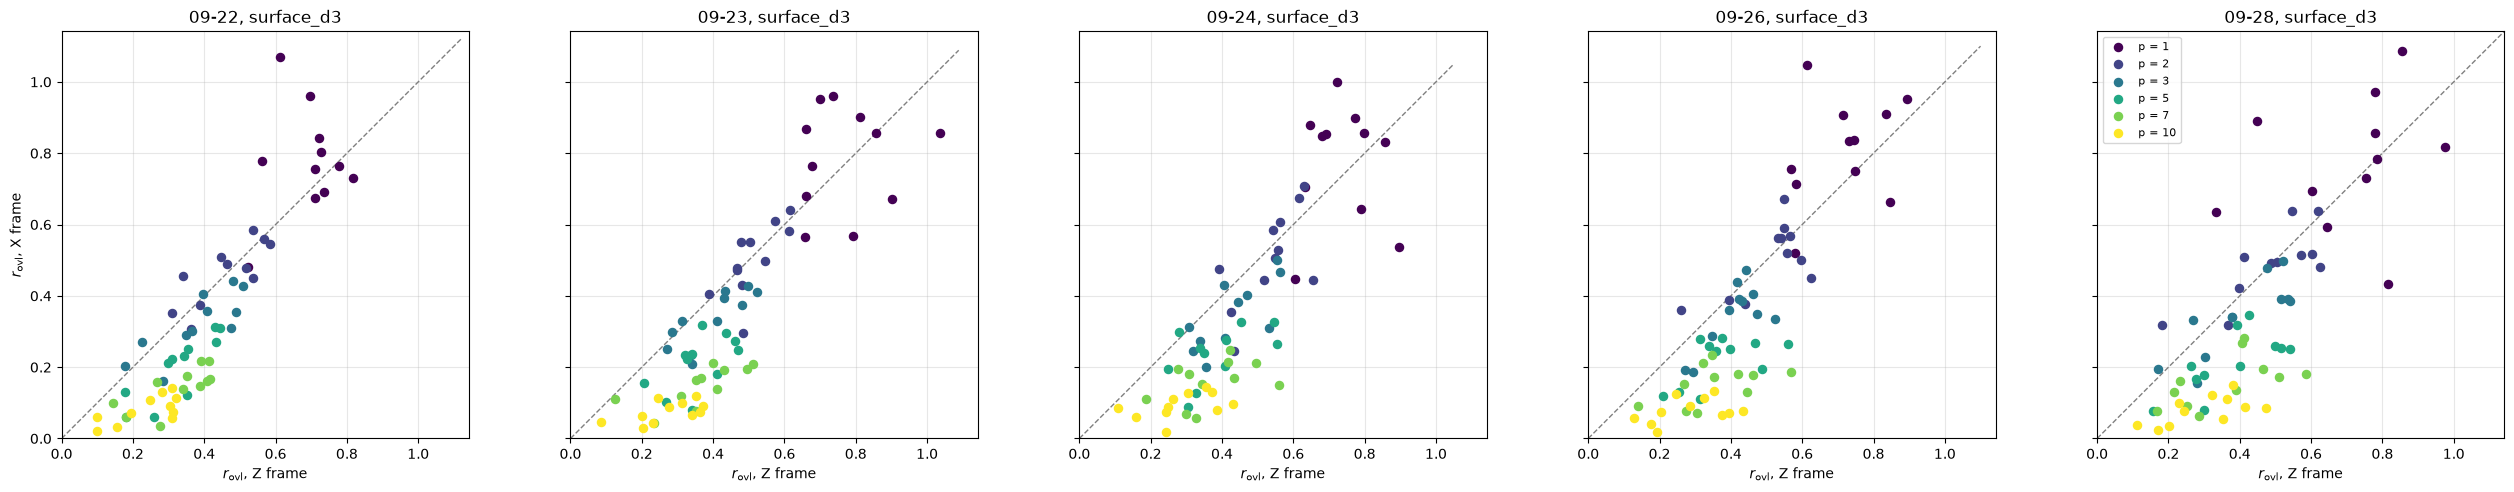

In [ ]:
x_camps = [c.label for c in campaigns if c.lrqaoa_x]
if not x_camps:
    print("no campaign with both frames yet")
else:
    fig, axes = plt.subplots(1, len(x_camps), figsize=(5.2 * len(x_camps), 4.8), squeeze=False, sharex=True, sharey=True)
    cmap = plt.get_cmap("viridis")
    for ax, c in zip(axes[0], x_camps):
        sub = [r for r in per[c] if r["r_ovl_x"]]
        for k, p in enumerate(P):
            zs = [r["r_ovl"][p] for r in sub]
            xs = [r["r_ovl_x"][p] for r in sub]
            ax.scatter(zs, xs, color=cmap(k / max(len(P) - 1, 1)), s=34, label=f"p = {p}", zorder=3)
            print(f"{c}  p = {p:>2}: mean r_ovl  Z {np.mean(zs):.3f}  X {np.mean(xs):.3f}  "
                  f"X - Z {np.mean(np.array(xs) - np.array(zs)):+.3f}   rho(Z, X) = {spearman(zs, xs)[0]:+.2f}")
        lim = [0, max(max(r["r_ovl"][p] for r in sub for p in P), max(r["r_ovl_x"][p] for r in sub for p in P)) * 1.05]
        ax.plot(lim, lim, "--", color="0.5", lw=1)
        ax.set(xlim=lim, ylim=lim, xlabel=r"$r_{\rm ovl}$, Z frame", title=f"{c}, surface_d{DISTANCE}")
        ax.grid(alpha=0.3)
        ax.set_aspect("equal")
    axes[0][0].set_ylabel(r"$r_{\rm ovl}$, X frame")
    axes[0][-1].legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    fig.savefig(FIGURES / f"{BACKEND}_campaigns_frames_against_each_other.pdf", bbox_inches="tight")
    plt.show()

### The best and worst patches, followed through depth

Only for a campaign that ran both frames. The `N_BEST` patches that kept the $X$ logical qubit best (lowest
$P_L^X$, ranked at every round count and averaged) and the `N_WORST` at the other end, each followed from the
first depth to the last: its $r_{\rm ovl}(p)$ against $P_L^X(R = p)$, the X frame solid and labelled with the
depth, the Z frame of the same patch dashed. If a frame measures what the memory does, the patches lie on one
curve and the worse ones simply sit further along it.

10-02: best by X memory  @64 (rank 1.0), @73 (rank 2.0), @3 (rank 3.0)
       worst by X memory @77 (rank 9.0), @32 (rank 10.0), @37 (rank 11.0)


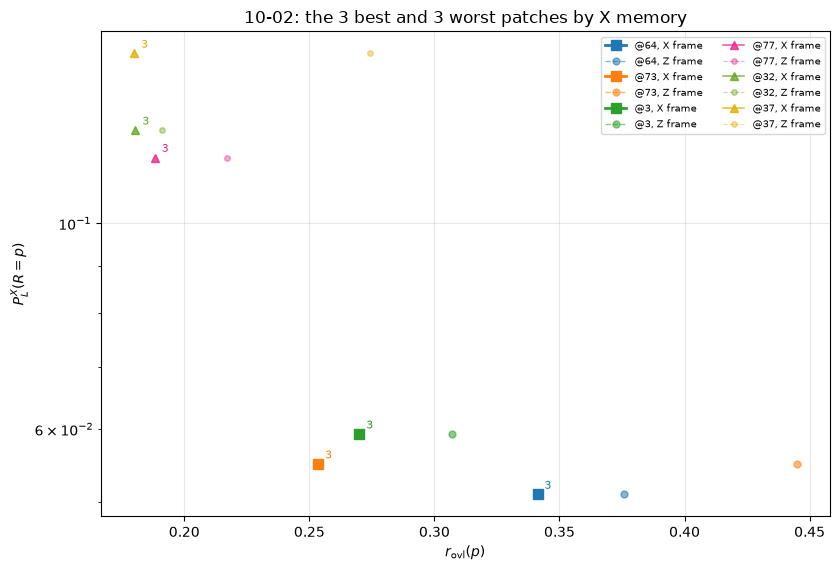

In [10]:
N_BEST, N_WORST = 3, 3
x_campaigns = [c.label for c in campaigns if c.lrqaoa_x]
if not x_campaigns:
    print("no campaign with both frames yet")
else:
    trail = per[x_campaigns[-1]]
    keys = {r["name"]: r for r in trail}
    mean_rank = {n: np.mean([sorted(trail, key=lambda r: r["P_L_X"][p]).index(keys[n]) + 1 for p in P])
                 for n in keys}
    order = sorted(keys, key=lambda n: mean_rank[n])
    best, worst = order[:N_BEST], (order[-N_WORST:] if N_WORST else [])
    print(f"{x_campaigns[-1]}: best by X memory  " + ", ".join(f"{n} (rank {mean_rank[n]:.1f})" for n in best))
    print(f"{' ' * len(x_campaigns[-1])}  worst by X memory " + ", ".join(f"{n} (rank {mean_rank[n]:.1f})" for n in worst))
    fig, ax = plt.subplots(figsize=(8.5, 5.8))
    groups = [(best, plt.get_cmap("tab10").colors, dict(marker="s", lw=2, ms=7), dict(lw=1, ms=5, alpha=0.55)),
              (worst, plt.get_cmap("Dark2").colors[3:], dict(marker="^", lw=1.1, ms=6, alpha=0.8),
               dict(lw=0.8, ms=4, alpha=0.4))]
    for chosen, colours, x_style, z_style in groups:
        for colour, n in zip(colours, chosen):
            r = keys[n]
            pl = [r["P_L_X"][p] for p in P]
            ax.plot([r["r_ovl_x"][p] for p in P], pl, "-", color=colour, label=f"{n}, X frame", **x_style)
            ax.plot([r["r_ovl"][p] for p in P], pl, "o--", color=colour, label=f"{n}, Z frame", **z_style)
            for p, xv, yv in zip(P, [r["r_ovl_x"][p] for p in P], pl):
                ax.annotate(f"{p}", (xv, yv), textcoords="offset points", xytext=(5, 4), fontsize=8, color=colour)
    ax.set(xlabel=r"$r_{\rm ovl}(p)$", ylabel=r"$P_L^X(R = p)$", yscale="log",
           title=f"{x_campaigns[-1]}: the {len(best)} best and {len(worst)} worst patches by X memory")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7.5, ncol=2)
    fig.tight_layout()
    fig.savefig(FIGURES / f"{BACKEND}_campaigns_frame_trajectories.pdf", bbox_inches="tight")
    plt.show()

### The benchmark against the calibration, depth by depth

Pooled $\rho$ against $P_L(R)$ at each $R$: the benchmark at the same depth, and each calibration number.


pooled rho against P_L^Z(R):
               predictor     R = 3
      benchmark, Z frame     +0.74
      benchmark, X frame     +0.79
           mean CZ error     +0.71
            round budget     +0.70
            data readout     +0.53
         ancilla readout     +0.20

pooled rho against P_L^X(R):
               predictor     R = 3
      benchmark, Z frame     +0.60
      benchmark, X frame     +0.81
           mean CZ error     +0.52
            round budget     +0.46
            data readout     +0.44
         ancilla readout     +0.00


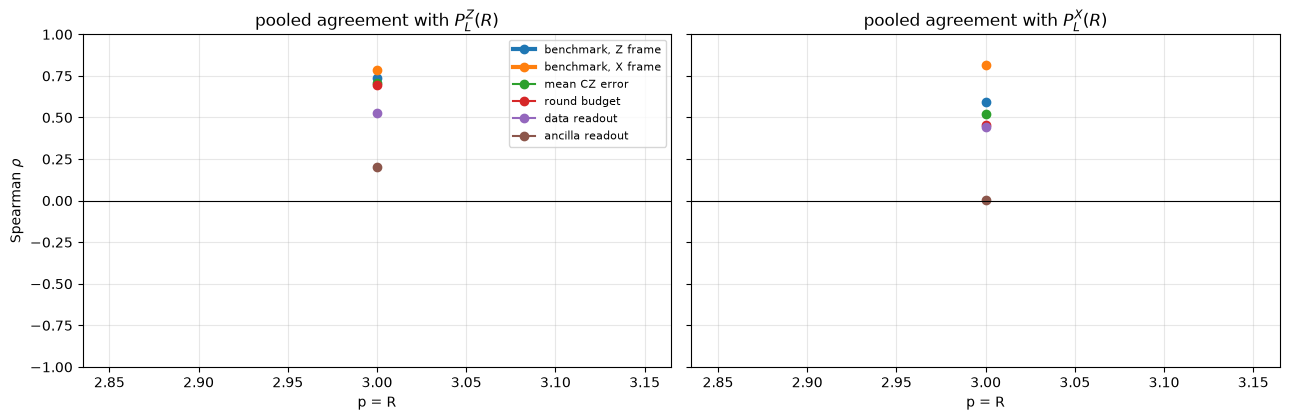

In [11]:
cal_preds = {f"benchmark, {frame}": pred for frame, pred in BENCH.items()}
cal_preds.update({"mean CZ error": "cz_mean", "round budget": "budget",
                  "data readout": "data_ro_mean", "ancilla readout": "anc_ro_mean"})
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, basis in zip(axes, ("Z", "X")):
    print(f"\npooled rho against P_L^{basis}(R):")
    print(f"{'predictor':>24} " + "".join(f"{'R = ' + str(p):>9}" for p in P))
    for name, pred in cal_preds.items():
        rho = [depth_rho(p, basis, predictor=pred)[0] for p in P]
        print(f"{name:>24} " + "".join(f"{v:>+9.2f}" for v in rho))
        ax.plot(P, rho, "o-", lw=3 if pred.startswith("r_ovl") else 1.5, label=name)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="p = R", title=f"pooled agreement with $P_L^{basis}(R)$", ylim=(-1, 1))
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"Spearman $\rho$")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_depth_vs_calibration.pdf", bbox_inches="tight")
plt.show()

## 6. Every predictor, campaign by campaign

Each patch reduced to its logical error rate after `R_REF` rounds, and every predictor - the benchmark score and
each calibration number - ranked against it, campaign by campaign. Every predictor is oriented so that larger
means worse (the benchmark enters as $-$score), so **positive means it ranks the patches the way the memory
experiment does**. The dotted lines mark the $\rho$ that $n$ patches need for $p < 0.05$ on its own.

**Read with care.** With about a dozen patches and nine predictors, two bases and several campaigns, a few
$p < 0.05$ appear by chance: a predictor counts when it agrees campaign after campaign, not in one of them.
The pooled column combines the same patches seen several times, so it gains resolution, not independence.


rho against P_L^Z after R = 3 rounds:
     predictor           09-14          09-18          09-21          09-22          09-23          09-24          09-26          09-28          09-29          09-30          10-02         pooled
          rank    +0.85 (0.00)   +0.65 (0.03)   +0.38 (0.25)   +0.80 (0.00)   +0.82 (0.00)   +0.81 (0.00)   +0.60 (0.05)   +0.76 (0.01)   +0.90 (0.00)   +0.88 (0.00)   +0.77 (0.01)   +0.71 (0.00)
        rank_x     +nan (nan)    +nan (nan)    +nan (nan)   +0.90 (0.00)   +0.77 (0.01)   +0.82 (0.00)   +0.76 (0.01)   +0.88 (0.00)   +0.76 (0.01)   +0.72 (0.01)   +0.70 (0.02)   +0.77 (0.00)
       cz_mean    +0.89 (0.00)   +0.59 (0.06)   +0.83 (0.00)   +0.65 (0.03)   +0.50 (0.12)   +0.43 (0.19)   +0.86 (0.00)   +0.79 (0.00)   +0.77 (0.01)   +0.84 (0.00)   +0.63 (0.04)   +0.68 (0.00)
        cz_max    +0.72 (0.01)   +0.56 (0.07)   +0.82 (0.00)   +0.36 (0.27)   +0.57 (0.07)   +0.49 (0.13)   +0.73 (0.01)   +0.89 (0.00)   +0.89 (0.00)   +0.89 (0.00)   +0.70 (0.02)

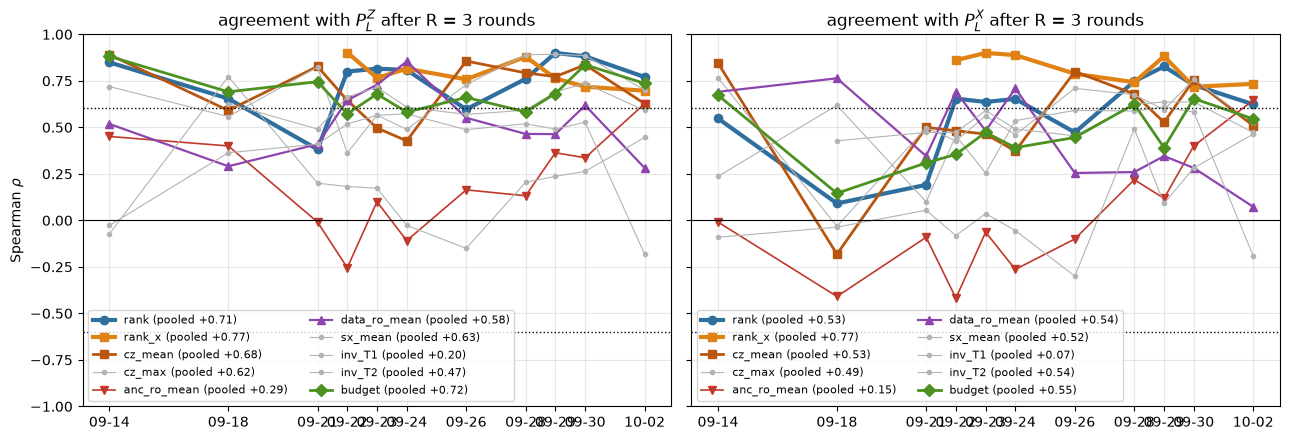

dotted: |rho| = 0.60, p = 0.05 for n = 11 patches


In [12]:
order = ["rank"] + (["rank_x"] if any(r["r_ovl_x"] for r in rows) else []) \
        + ["cz_mean", "cz_max", "anc_ro_mean", "data_ro_mean", "sx_mean", "inv_T1", "inv_T2", "budget"]
table = {(pred, target): agreement(rows, pred, target) for pred in order for target in ("mem_Z", "mem_X")}
for target in ("mem_Z", "mem_X"):
    print(f"\nrho against P_L^{target[-1]} after R = {R_REF} rounds:")
    print(f"{'predictor':>14} " + "".join(f"{c:>15}" for c in labels) + f"{'pooled':>15}")
    for pred in order:
        a = table[(pred, target)]
        print(f"{pred:>14} " + "".join(f"{a[c][0]:>+8.2f} ({a[c][1]:.2f})" for c in labels + ["pooled"]))

n = int(np.median([len(per[c]) for c in labels]))
tcrit = student_t.ppf(0.975, n - 2)
rho_crit = tcrit / np.sqrt(n - 2 + tcrit ** 2)
style = {"rank": ("#2f6f9f", "o", 3.0), "rank_x": ("#e08214", "s", 3.0), "cz_mean": ("#b8560f", "s", 2.0),
         "budget": ("#4d9221", "D", 2.0), "data_ro_mean": ("#8e44ad", "^", 1.6), "anc_ro_mean": ("#c0392b", "v", 1.2)}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, target in zip(axes, ("mem_Z", "mem_X")):
    for pred in order:
        colour, marker, lw = style.get(pred, ("0.7", ".", 0.8))
        rho = [table[(pred, target)][c][0] for c in labels]
        ax.plot(x, rho, marker=marker, color=colour, lw=lw, label=f"{pred} (pooled {table[(pred, target)]['pooled'][0]:+.2f})")
    for sign in (+1, -1):
        ax.axhline(sign * rho_crit, color="k", ls=":", lw=1)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=f"agreement with $P_L^{target[-1]}$ after R = {R_REF} rounds", ylim=(-1, 1))
    ax.set_xticks(x, labels)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="lower left", ncol=2)
axes[0].set_ylabel(r"Spearman $\rho$")
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_agreement.pdf", bbox_inches="tight")
plt.show()
print(f"dotted: |rho| = {rho_crit:.2f}, p = 0.05 for n = {n} patches")

### The benchmark against the memory, campaign by campaign

Each patch as a point: its benchmark score against its logical error rate after `R_REF` rounds (log scale).
The patches the benchmark would pick are ringed; the ones that really kept the logical qubit longest (`OUTCOME`)
are marked with a star.

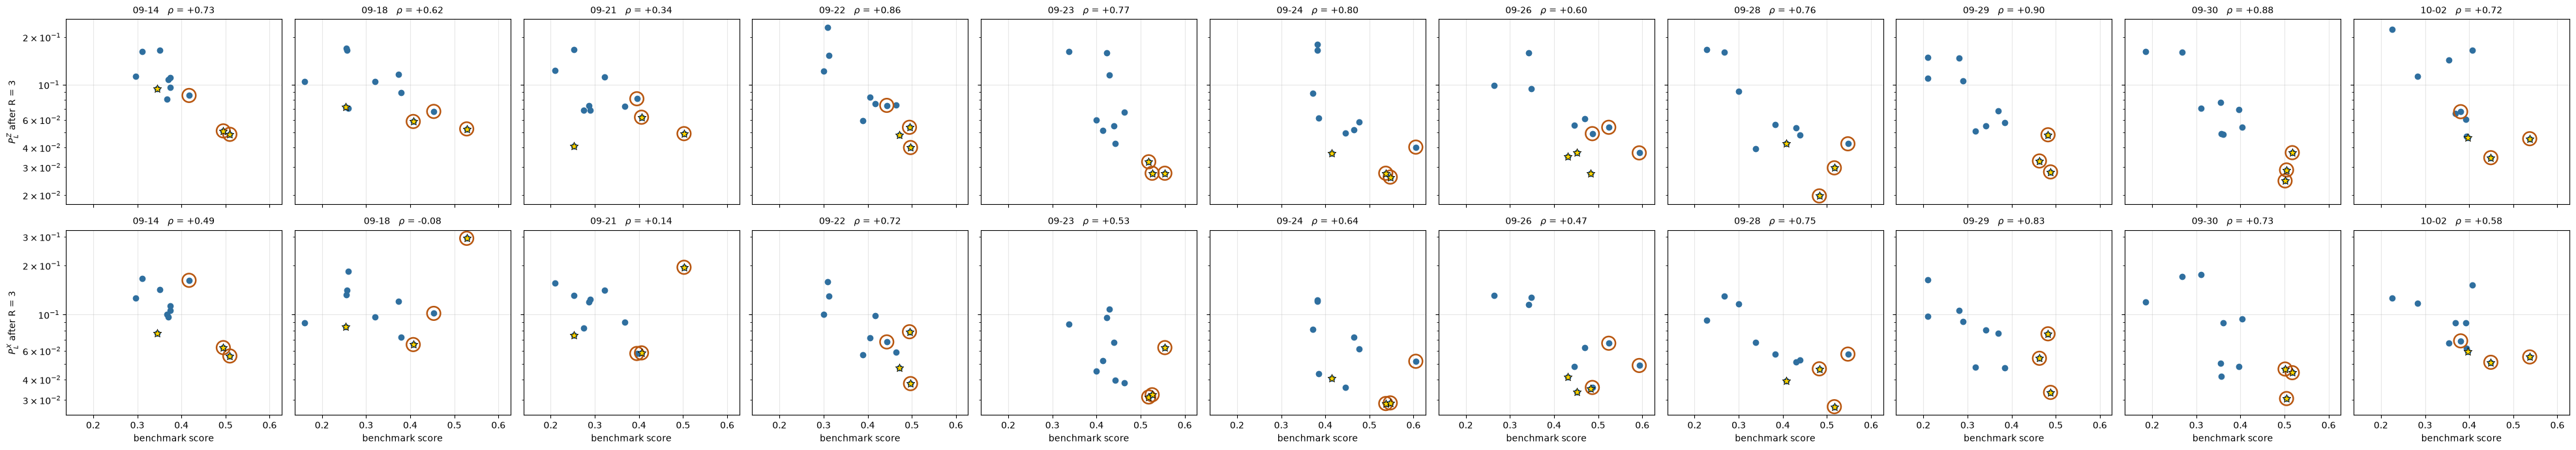

In [13]:
fig, axes = plt.subplots(2, len(labels), figsize=(3.6 * len(labels), 7), sharex=True, sharey="row", squeeze=False)
for j, c in enumerate(labels):
    sub = per[c]
    chosen = {r["name"] for r in pick(sub, "rank", TOP)}
    best = {r["name"] for r in sorted(sub, key=lambda r: (-r[OUTCOME], r["mem_Z"]))[:TOP]}
    for i, basis in enumerate(("Z", "X")):
        ax = axes[i, j]
        for r in sub:
            ax.scatter(r["score"], r[f"mem_{basis}"], color="#2f6f9f", zorder=3)
            if r["name"] in chosen:
                ax.scatter(r["score"], r[f"mem_{basis}"], s=220, facecolor="none", edgecolor="#b8560f", lw=1.8, zorder=4)
            if r["name"] in best:
                ax.scatter(r["score"], r[f"mem_{basis}"], marker="*", s=90, color="gold", edgecolor="k", lw=0.6, zorder=5)
        rho = spearman([-r["score"] for r in sub], [r[f"mem_{basis}"] for r in sub])[0]
        ax.set_title(f"{c}   $\\rho$ = {rho:+.2f}", fontsize=10)
        ax.set_yscale("log")
        ax.grid(alpha=0.3)
        if j == 0:
            ax.set_ylabel(rf"$P_L^{basis}$ after R = {R_REF}")
    axes[1, j].set_xlabel("benchmark score")
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_scatter.pdf", bbox_inches="tight")
plt.show()

## 7. Picking the best patches

Each method picks its `TOP` patches in every campaign: the benchmark (highest score), the CZ error, the
round budget and the data readout (lowest). A pick is judged by `OUTCOME` of the patches it chose, against the
typical patch (all of them) and the best `TOP` there were. A method that sits at "best possible" found the good
patches; one at "typical" did no better than choosing blind.

/var/folders/76/d4kyjysx1xgdrrs6zzs63s180000gn/T/ipykernel_78662/2796532277.py:244: RuntimeWarning: Mean of empty slice
  out[c] = (float(np.nanmean(chosen)), float(np.mean(values)), float(np.mean(sorted(values)[-k:])))


mean life of the 3 patches each method picks
        method     09-14    09-18    09-21    09-22    09-23    09-24    09-26    09-28    09-29    09-30    10-02     mean
benchmark Z frame      6.33     6.33     6.00     8.00    11.33    12.67     8.67    11.33     6.00     6.00     8.00     8.24
benchmark X frame       nan      nan      nan     8.67    11.33    12.67     9.33    12.00     6.00     6.00     7.33      nan
      CZ error      6.33     5.33     6.33     9.33     9.33     9.33    10.67    11.33     6.00     6.00     8.00     8.00
  round budget      6.33     6.33     6.67     8.00     9.33    10.00     9.33     8.67     5.00     6.00     6.67     7.48
  data readout      6.67     6.33     5.67     8.67    11.33    12.67     9.33     8.67     6.00     6.00     6.67     8.00
 typical patch      4.91     5.09     5.45     6.45     7.91     8.64     7.64     7.91     4.36     4.64     6.00     6.27
 best possible      6.67     6.67     6.67     9.33    11.33    12.67    10.67   

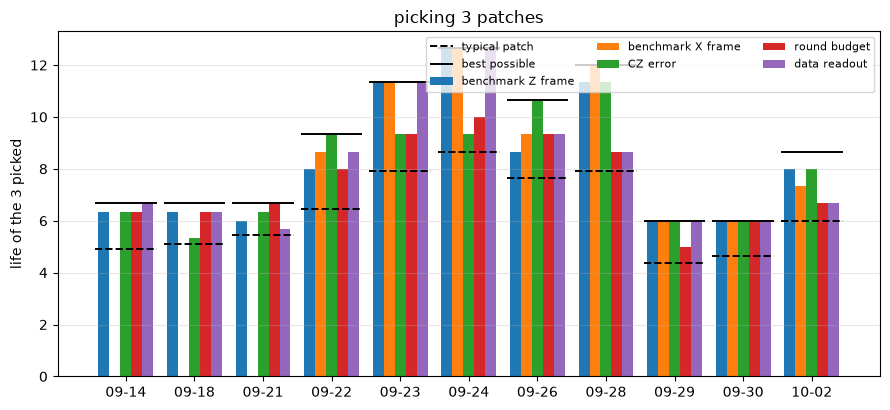


what each method picked:
  09-14: benchmark Z frame: @63, @72, @64   benchmark X frame:    CZ error: @72, @73, @63   round budget: @72, @73, @63   data readout: @63, @72, @3   | best memory: @72, @63, @3
  09-18: benchmark Z frame: @73, @75, @72   benchmark X frame:    CZ error: @75, @3, @73   round budget: @75, @73, @72   data readout: @72, @3, @63   | best memory: @72, @73, @25
  09-21: benchmark Z frame: @73, @64, @63   benchmark X frame:    CZ error: @72, @63, @4   round budget: @72, @73, @63   data readout: @3, @63, @75   | best memory: @72, @73, @63
  09-22: benchmark Z frame: @72, @73, @64   benchmark X frame: @63, @72, @64   CZ error: @73, @72, @63   round budget: @75, @72, @73   data readout: @72, @3, @63   | best memory: @72, @63, @73
  09-23: benchmark Z frame: @73, @72, @63   benchmark X frame: @72, @63, @64   CZ error: @4, @3, @73   round budget: @75, @72, @73   data readout: @72, @63, @3   | best memory: @72, @63, @73
  09-24: benchmark Z frame: @73, @63, @72   benchmark

In [14]:
methods = {"benchmark Z frame": "rank", "CZ error": "cz_mean", "round budget": "budget",
           "data readout": "data_ro_mean"}
if any(r["r_ovl_x"] for r in rows):
    methods = {"benchmark Z frame": "rank", "benchmark X frame": "rank_x", **methods}
picks = {m: selection(rows, pred, OUTCOME, TOP) for m, pred in methods.items()}
print(f"mean {OUTCOME} of the {TOP} patches each method picks")
print(f"{'method':>14} " + "".join(f"{c:>9}" for c in labels) + f"{'mean':>9}")
for m in methods:
    v = [picks[m][c][0] for c in labels]
    print(f"{m:>14} " + "".join(f"{u:>9.2f}" for u in v) + f"{np.mean(v):>9.2f}")
for k, label in ((1, "typical patch"), (2, "best possible")):
    v = [picks[next(iter(methods))][c][k] for c in labels]
    print(f"{label:>14} " + "".join(f"{u:>9.2f}" for u in v) + f"{np.mean(v):>9.2f}")

fig, ax = plt.subplots(figsize=(9, 4.2))
width = 0.8 / len(methods)
for k, m in enumerate(methods):
    ax.bar(np.arange(len(labels)) + (k - (len(methods) - 1) / 2) * width, [picks[m][c][0] for c in labels],
           width, label=m)
for k, name, ls in ((1, "typical patch", "--"), (2, "best possible", "-")):
    ax.hlines([picks[next(iter(methods))][c][k] for c in labels], np.arange(len(labels)) - 0.45, np.arange(len(labels)) + 0.45,
              colors="k", linestyles=ls, lw=1.4, label=name)
ax.set_xticks(range(len(labels)), labels)
ax.set(ylabel=f"{OUTCOME} of the {TOP} picked", title=f"picking {TOP} patches")
ax.legend(fontsize=8, ncol=3)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_selection.pdf", bbox_inches="tight")
plt.show()

print("\nwhat each method picked:")
for c in labels:
    actual = sorted(per[c], key=lambda r: (-r[OUTCOME], r["mem_Z"]))[:TOP]
    print(f"  {c}: " + "   ".join(f"{m}: {', '.join(r['name'] for r in pick(per[c], p, TOP))}"
                               for m, p in methods.items())
          + f"   | best memory: {', '.join(r['name'] for r in actual)}")

### The patches that stay good

Every patch's mean rank over all campaigns, by each measurement, and where the patches sit on the chip (the chip
drawn from the couplers of the latest calibration snapshot). The `TOP` patches of the memory experiment are
outlined in black. Neighbouring placements share qubits, so several good patches in one corner are one good
region of the chip rather than independent choices.

mean rank over the campaigns (1 = best)
 patch    benchmark score      P_L^Z at R=3      P_L^X at R=3     mean CZ error   memory, Z and X
   @72                3.5               1.6               2.9               3.5               2.3
   @63                3.2               2.8               1.8               3.0               2.3
    @3                6.9               4.3               4.7               4.7               4.5
   @73                1.7               2.9               6.4               2.5               4.6
    @4                6.7               5.8               4.9               3.7               5.4
   @25                6.5               6.2               4.6               9.8               5.4
   @64                4.5               6.5               5.1               6.5               5.8
   @75                5.1               6.1               6.5               4.6               6.3
   @77                8.7               9.3               9.7               8.

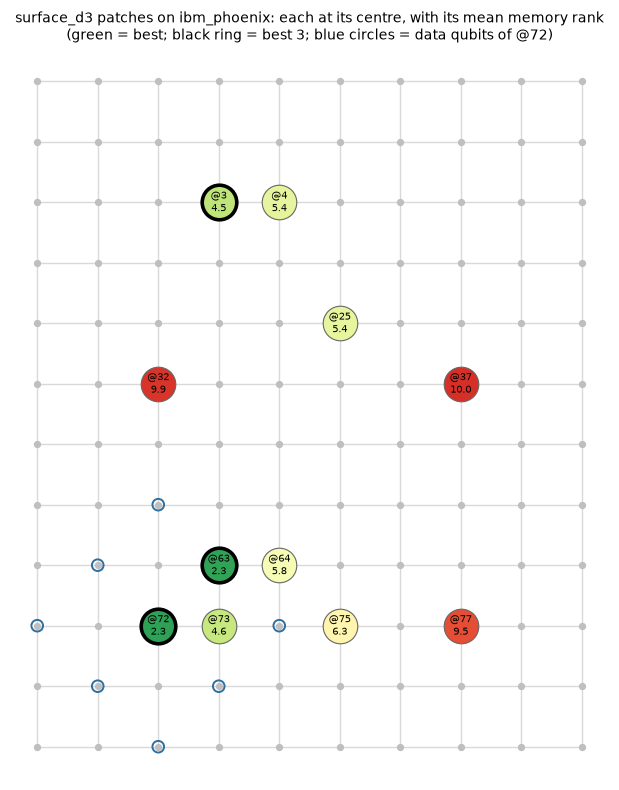

In [15]:
mean_rank = {}
for metric, title, high in rank_panels:
    R = ranks(metric, high)
    mean_rank[metric] = {name: np.nanmean(R[i]) for i, name in enumerate(names)}
memory_rank = {n: (mean_rank["mem_Z"][n] + mean_rank["mem_X"][n]) / 2 for n in names}
print("mean rank over the campaigns (1 = best)")
print(f"{'patch':>6} " + "".join(f"{PLAIN[m]:>18}" for m, _, _ in rank_panels) + f"{'memory, Z and X':>18}")
for n_ in sorted(names, key=lambda n: memory_rank[n]):
    print(f"{n_:>6} " + "".join(f"{mean_rank[m][n_]:>18.1f}" for m, _, _ in rank_panels) + f"{memory_rank[n_]:>18.1f}")
winners = sorted(names, key=lambda n: memory_rank[n])[:TOP]
by_benchmark = sorted(names, key=lambda n: mean_rank["score"][n])[:TOP]
print(f"\nbest {TOP} by the memory experiment, over all campaigns: {', '.join(winners)}")
print(f"best {TOP} by the benchmark, over all campaigns:         {', '.join(by_benchmark)}"
      f"   ({len(set(winners) & set(by_benchmark))} of {TOP} the same)")

latest = max((c for c in campaigns if c.calibration), key=lambda c: c.day)
G = chip_graph(latest.calibration)
coords = square_lattice_coordinates(G)
patch_of = {r["name"]: r["patch"] for r in rows}
fig, ax = plt.subplots(figsize=(7, 8))
for u, v in G.edges:
    (r1, c1), (r2, c2) = coords[u], coords[v]
    ax.plot([c1, c2], [-r1, -r2], color="0.85", lw=1, zorder=0)
ax.scatter([c for r, c in coords.values()], [-r for r, c in coords.values()], s=18, color="0.75", zorder=1)
cmap = plt.get_cmap("RdYlGn_r")
for q in patch_of[winners[0]]:                  # the qubits of the best patch, for scale
    r, c = coords[q]
    ax.scatter(c, -r, s=70, facecolor="none", edgecolor="#2f6f9f", lw=1.4, zorder=2)
for n_ in names:
    rc = np.array([coords[q] for q in patch_of[n_]], float).mean(axis=0)
    ax.scatter(rc[1], -rc[0], s=620, color=cmap((memory_rank[n_] - 1) / max(len(names) - 1, 1)),
               edgecolor="k" if n_ in winners else "0.4", lw=2.6 if n_ in winners else 0.8, zorder=3)
    ax.text(rc[1], -rc[0], f"{n_}\n{memory_rank[n_]:.1f}", ha="center", va="center", fontsize=7.5, zorder=4)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"surface_d{DISTANCE} patches on {BACKEND}: each at its centre, with its mean memory rank\n"
             f"(green = best; black ring = best {TOP}; blue circles = data qubits of {winners[0]})", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_campaigns_chip.pdf", bbox_inches="tight")
plt.show()

## 8. What changed in the latest campaign

The newest campaign against the one before it, in numbers: the chip-wide medians, how much the patch rankings
moved, and whether the agreement between benchmark and memory went up or down.

In [16]:
if len(labels) < 2:
    print("one campaign only - nothing to compare yet")
else:
    new, old = labels[-1], labels[-2]
    print(f"{new} against {old}")
    for metric, title, _ in panels:
        a, b = (np.nanmedian([r[metric] for r in per[c]]) for c in (old, new))
        print(f"  {PLAIN[metric]:>18}: {a:.4f} -> {b:.4f}  ({100 * (b - a) / a:+.0f} %)")
    for metric, title, _ in rank_panels:
        rho = stability(rows, metric)[(old, new)][0]
        print(f"  {PLAIN[metric]:>18}: ranking kept with rho = {rho:+.2f}")
    for target in ("mem_Z", "mem_X"):
        for pred in [p for p in ("rank", "rank_x", "cz_mean", "budget") if p in order]:
            a, b = table[(pred, target)][old][0], table[(pred, target)][new][0]
            print(f"  agreement of {pred:>8} with {target}: {a:+.2f} -> {b:+.2f}")

10-02 against 09-30
     benchmark score: 0.3606 -> 0.3925  (+9 %)
        P_L^Z at R=3: 0.0540 -> 0.0658  (+22 %)
        P_L^X at R=3: 0.0502 -> 0.0690  (+38 %)
       mean CZ error: 0.0022 -> 0.0033  (+52 %)
     ancilla readout: 0.0074 -> 0.0069  (-6 %)
        data readout: 0.0072 -> 0.0062  (-14 %)
     benchmark score: ranking kept with rho = +0.35
        P_L^Z at R=3: ranking kept with rho = +0.46
        P_L^X at R=3: ranking kept with rho = +0.43
       mean CZ error: ranking kept with rho = +0.89
  agreement of     rank with mem_Z: +0.88 -> +0.77
  agreement of   rank_x with mem_Z: +0.72 -> +0.70
  agreement of  cz_mean with mem_Z: +0.84 -> +0.63
  agreement of   budget with mem_Z: +0.84 -> +0.74
  agreement of     rank with mem_X: +0.73 -> +0.62
  agreement of   rank_x with mem_X: +0.72 -> +0.73
  agreement of  cz_mean with mem_X: +0.75 -> +0.51
  agreement of   budget with mem_X: +0.65 -> +0.55


## 9. What the campaigns support so far

A summary computed from everything above, so it changes as campaigns are added. For each memory basis: the
pooled agreement of each benchmark frame and of the best calibration number, campaign by campaign; how much the
chip re-ordered its own patches between campaigns (if it barely moved, that campaign tests little); and how well
each measurement reproduces itself. Read the frames against the memory of their own basis first.

In [17]:
best_cal = ["cz_mean", "budget", "data_ro_mean", "anc_ro_mean", "sx_mean", "inv_T1", "inv_T2"]
def pooled_rho(pred, basis, campaign):
    return depth_rho(P[1], basis, predictor=pred, campaign=campaign)[0] if False else np.nanmean(
        [depth_rho(p, basis, predictor=pred, campaign=campaign)[0] for p in P[1:]])

for basis in ("Z", "X"):
    print(f"\nmemory {basis}: mean rho over p = R >= 2, per campaign")
    print(f"{'campaign':>9} " + "".join(f"{h:>18}" for h in BENCH) + f"{'best calibration':>24}")
    for c in labels:
        cells = [pooled_rho(pred, basis, c) for pred in BENCH.values()]
        cal = {name: pooled_rho(name, basis, c) for name in best_cal}
        top = max(cal, key=lambda k: cal[k])
        print(f"{c:>9} " + "".join(f"{v:>18.2f}" for v in cells) + f"{f'{cal[top]:.2f} ({top})':>24}")

print("\nhow much the chip re-ordered itself between campaigns (Spearman of P_L at R = 3)")
for basis in ("Z", "X"):
    pairs = []
    for a, b in zip(labels, labels[1:]):
        va = {r["patch"]: r[f"P_L_{basis}"][3] for r in per[a]}
        vb = {r["patch"]: r[f"P_L_{basis}"][3] for r in per[b]}
        common = sorted(set(va) & set(vb))
        pairs.append(f"{a}->{b} {spearman([va[k] for k in common], [vb[k] for k in common])[0]:+.2f}")
    print(f"  {basis}: " + "   ".join(pairs))

print("\nreproducibility of each measurement between campaigns (Spearman)")
for label, metric in [("benchmark Z frame", "rank"), ("benchmark X frame", "rank_x"),
                      ("memory P_L^Z(R=3)", "mem_Z"), ("memory P_L^X(R=3)", "mem_X"), ("mean CZ error", "cz_mean")]:
    pairs = stability(rows, metric)
    got = [f"{a}->{b} {v[0]:+.2f}" for (a, b), v in pairs.items() if np.isfinite(v[0])]
    print(f"  {label:>19}: " + ("   ".join(got) if got else "not run in two campaigns yet"))


memory Z: mean rho over p = R >= 2, per campaign
 campaign            Z frame           X frame        best calibration
    09-14                nan               nan           nan (cz_mean)
    09-18                nan               nan           nan (cz_mean)
    09-21                nan               nan           nan (cz_mean)
    09-22                nan               nan           nan (cz_mean)
    09-23                nan               nan           nan (cz_mean)
    09-24                nan               nan           nan (cz_mean)
    09-26                nan               nan           nan (cz_mean)
    09-28                nan               nan           nan (cz_mean)
    09-29                nan               nan           nan (cz_mean)
    09-30                nan               nan           nan (cz_mean)
    10-02                nan               nan           nan (cz_mean)

memory X: mean rho over p = R >= 2, per campaign
 campaign            Z frame           X frame  

/var/folders/76/d4kyjysx1xgdrrs6zzs63s180000gn/T/ipykernel_78662/1922020582.py:3: RuntimeWarning: Mean of empty slice
  return depth_rho(P[1], basis, predictor=pred, campaign=campaign)[0] if False else np.nanmean(


    memory P_L^X(R=3): 09-14->09-18 +0.50   09-14->09-21 +0.40   09-14->09-22 +0.65   09-14->09-23 +0.65   09-14->09-24 +0.74   09-14->09-26 +0.80   09-14->09-28 +0.63   09-14->09-29 +0.55   09-14->09-30 +0.59   09-14->10-02 +0.23   09-18->09-21 +0.81   09-18->09-22 +0.75   09-18->09-23 +0.65   09-18->09-24 +0.65   09-18->09-26 +0.52   09-18->09-28 +0.38   09-18->09-29 +0.42   09-18->09-30 +0.21   09-18->10-02 -0.01   09-21->09-22 +0.75   09-21->09-23 +0.85   09-21->09-24 +0.62   09-21->09-26 +0.61   09-21->09-28 +0.56   09-21->09-29 +0.50   09-21->09-30 +0.37   09-21->10-02 +0.32   09-22->09-23 +0.90   09-22->09-24 +0.96   09-22->09-26 +0.88   09-22->09-28 +0.69   09-22->09-29 +0.85   09-22->09-30 +0.75   09-22->10-02 +0.33   09-23->09-24 +0.85   09-23->09-26 +0.90   09-23->09-28 +0.75   09-23->09-29 +0.76   09-23->09-30 +0.75   09-23->10-02 +0.44   09-24->09-26 +0.94   09-24->09-28 +0.72   09-24->09-29 +0.91   09-24->09-30 +0.84   09-24->10-02 +0.29   09-26->09-28 +0.78   09-26->09-2

## 10. The logical error, with the patches in the order the benchmark ranks them

One sitting, read the way the benchmark would be used: the patches are laid out from the one the benchmark scores
best to the one it scores worst, and each bar is that patch's measured logical error probability. If the benchmark
ranked the patches exactly as the memory does, the bars would climb from left to right along the dashed staircase;
every bar that stands above or below it is a patch the benchmark has misplaced, and the number on top is the rank
the memory itself gives that patch.

Three orderings are shown: by the $X$ frame against $P_L^X$, by the $Z$ frame against $P_L^Z$, and by the two frames
together (the mean of a patch's two ranks) against the mean of the two memories.

`SITTING` picks the benchmark run by its stamp (`None` takes the newest that has both frames and a memory run beside
it), and `DEPTH` the depth $p$, compared with the memory after $R = p$ rounds.

20261002_1218: benchmark at p = 3 against the memory after R = 3 rounds (20261002_1213), 11 patches

   sorted by r_{\rm ovl}^{X}: rho +0.73, mean shift 1.64   order @64(1) @63(7) @75(4) @25(6) @3(3) @73(2) @72(8) @4(5) @77(9) @32(10) @37(11)
   sorted by r_{\rm ovl}^{Z}: rho +0.73, mean shift 2.00   order @73(2) @63(6) @64(1) @25(7) @72(5) @75(4) @3(3) @37(10) @77(8) @32(11) @4(9)
       sorted by both frames: rho +0.77, mean shift 1.45   order @63(7) @64(1) @73(2) @25(5) @75(4) @3(3) @72(6) @77(9) @4(8) @37(10) @32(11)


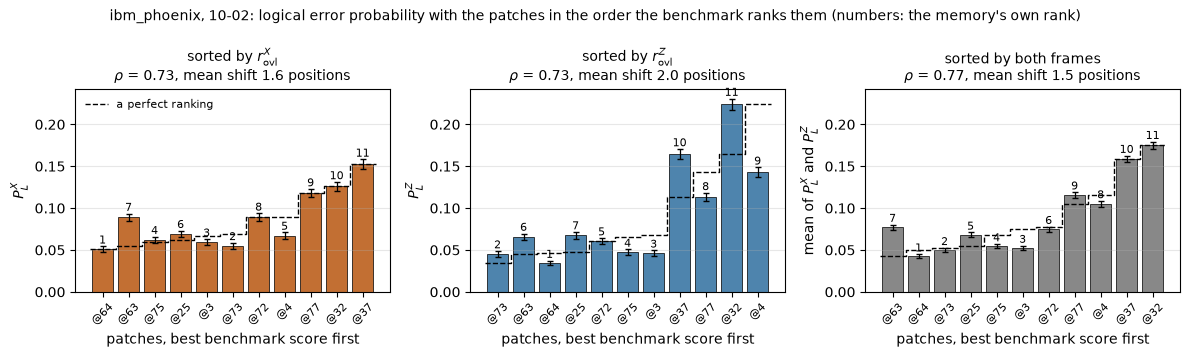

In [18]:
import re
from datetime import datetime

from scipy.stats import rankdata, spearmanr

from qecbench import memory as mem
from qecbench.analysis import load_results

SITTING = None        # stamp of the benchmark run, e.g. "20261002_0913"; None takes the newest with both frames
DEPTH   = 3           # the benchmark depth p, compared with the memory after R = p rounds

surface = DATA / "results" / BACKEND / "surface_code"
when = lambda path: datetime.strptime(re.match(r"\d{8}_\d{4}", path.name).group(0), "%Y%m%d_%H%M")
sittings_ = {}
for x_path in sorted((surface / "mcm_x").glob("*.json")):
    z_path = surface / "mcm" / x_path.name.replace("_mcm_x", "_mcm")
    near = [m for m in (surface / "memory").glob("*.json")
            if abs((when(m) - when(x_path)).total_seconds()) <= 3 * 3600]
    if z_path.exists() and near:
        sittings_[x_path.name[:13]] = (z_path, x_path,
                                       min(near, key=lambda m: abs((when(m) - when(x_path)).total_seconds())))
stamp_ = max(sittings_) if SITTING is None else next(k for k in sittings_ if k.startswith(SITTING))
z_path, x_path, m_path = sittings_[stamp_]
bench = {"Z": load_results(DATA / "results", BACKEND, kind="mcm", files={z_path.name}),
         "X": load_results(DATA / "results", BACKEND, kind="mcm_x", files={x_path.name})}
logical_ = mem.load_results(DATA / "results", BACKEND, files={m_path.name})
shown_ = sorted((q for q in bench["X"] if q in bench["Z"] and q in logical_ and q.code.info.get("distance") == DISTANCE
                 and DEPTH in bench["X"][q] and DEPTH in logical_[q]["X"]), key=lambda q: min(q.data_qubits))
rank_of = {f: rankdata([-bench[f][q][DEPTH]["r_ovl"] for q in shown_]) for f in "XZ"}      # 1 = best score
rate = {b: np.array([logical_[q][b][DEPTH]["rate"] for q in shown_]) for b in "XZ"}
error = {b: np.array([logical_[q][b][DEPTH]["err"] for q in shown_]) for b in "XZ"}
# three orderings by the benchmark, each against the memory it is meant to predict
panels_ = [(r"sorted by $r_{\rm ovl}^{X}$", rank_of["X"], rate["X"], error["X"], r"$P_L^X$", "#b8560f"),
           (r"sorted by $r_{\rm ovl}^{Z}$", rank_of["Z"], rate["Z"], error["Z"], r"$P_L^Z$", "#2f6f9f"),
           ("sorted by both frames", rankdata((rank_of["X"] + rank_of["Z"]) / 2), (rate["X"] + rate["Z"]) / 2,
            np.hypot(error["X"], error["Z"]) / 2, r"mean of $P_L^X$ and $P_L^Z$", "0.45")]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
print(f"{stamp_}: benchmark at p = {DEPTH} against the memory after R = {DEPTH} rounds ({m_path.name[:13]}), "
      f"{len(shown_)} patches\n")
for ax, (title, score, values, bars, label, colour) in zip(axes, panels_):
    order = np.argsort(score, kind="stable")                 # left: the patch the benchmark likes best
    truth = rankdata(values)                                 # 1 = lowest logical error
    ax.bar(range(len(order)), values[order], yerr=bars[order], color=colour, alpha=0.85, edgecolor="black",
           linewidth=0.6, error_kw={"elinewidth": 0.9, "capsize": 2})
    ax.step(np.arange(len(order) + 1) - 0.5, np.append(np.sort(values), np.sort(values)[-1]), where="post",
            color="black", lw=1, ls="--", label="a perfect ranking")
    for k, i in enumerate(order):                            # the rank the memory itself gives that patch
        ax.text(k, values[i] + bars[i], f"{int(truth[i])}", ha="center", va="bottom", fontsize=8)
    rho = spearmanr(score, truth)[0]
    shift = np.mean(np.abs(rankdata(score) - truth))
    ax.set_xticks(range(len(order)), [f"@{min(shown_[i].data_qubits)}" for i in order], fontsize=8, rotation=45)
    ax.set_title(f"{title}\n" + rf"$\rho$ = {rho:.2f}, mean shift {shift:.1f} positions", fontsize=10)
    ax.set_xlabel("patches, best benchmark score first")
    ax.set_ylabel(label)
    ax.yaxis.set_tick_params(labelleft=True)
    ax.grid(axis="y", alpha=0.3)
    print(f"{title.replace('$', ''):>28}: rho {rho:+.2f}, mean shift {shift:.2f}   order " +
          " ".join(f"@{min(shown_[i].data_qubits)}({int(truth[i])})" for i in order))
axes[0].legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle(f"{BACKEND}, {stamp_[4:6]}-{stamp_[6:8]}: logical error probability with the patches in the order "
             f"the benchmark ranks them (numbers: the memory's own rank)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_logical_error_sorted_by_benchmark.pdf", bbox_inches="tight")
plt.show()

## 11. The three frames against the memory

The run of 10-02 12:18 has the benchmark in its three frames - Z, X, and XZ (every check in the basis the surface
code gives it, under a $Y$ mixer) - next to a memory run on the same patches. Top: $r_{\rm ovl}$ against depth in
each frame, one line per patch, coloured by the rank the memory gives that patch (dark is the lowest $P_L$).
Bottom: the mean of $P_L^X$ and $P_L^Z$ after $R = p$ rounds, with the patches in the order each frame ranks them
at that depth; the number on a bar is the memory's own rank and the dashed staircase a perfect ranking.

 Z frame: rho +0.70, mean shift 2.00   order @73(2) @63(7) @64(1) @25(5) @72(6) @75(4) @3(3) @37(10) @77(9) @32(11) @4(8)
 X frame: rho +0.77, mean shift 1.45   order @64(1) @63(7) @75(4) @25(5) @3(3) @73(2) @72(6) @4(8) @77(9) @32(11) @37(10)
XZ frame: rho +0.87, mean shift 1.09   order @64(1) @73(2) @63(7) @75(4) @3(3) @25(5) @4(8) @72(6) @37(10) @77(9) @32(11)


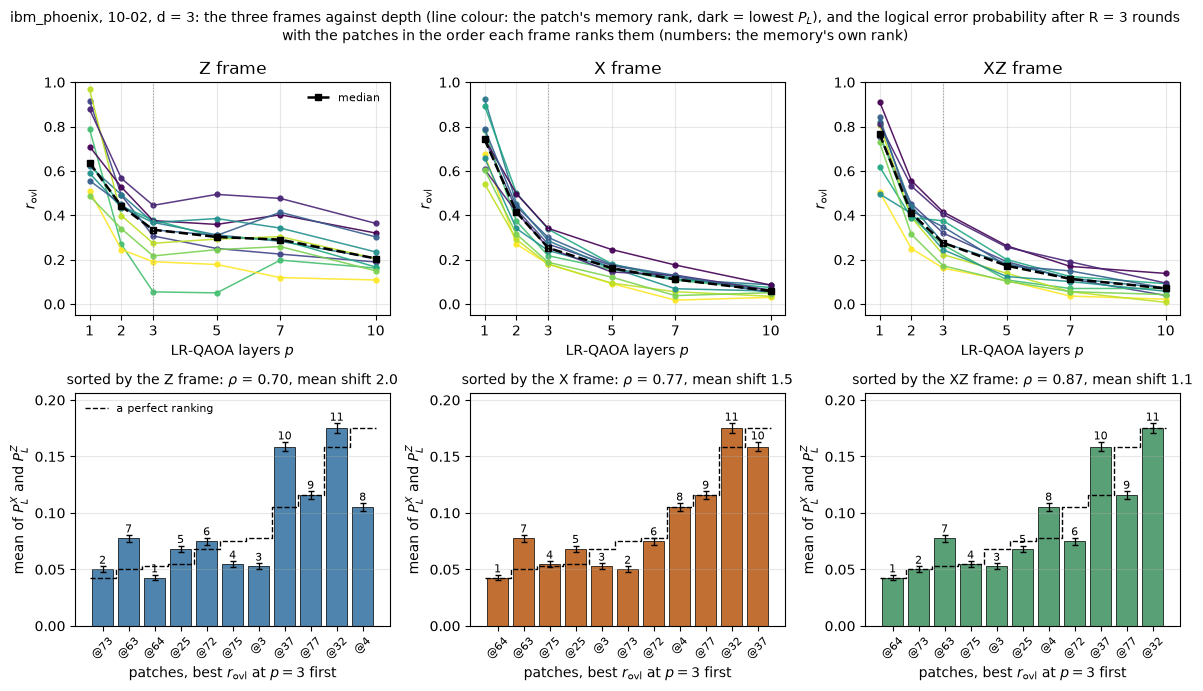

In [19]:
from scipy.stats import rankdata, spearmanr

from qecbench import memory as mem
from qecbench.analysis import load_results

STAMP3   = "20261002_121845"        # the benchmark run with the three frames
MEMORY3  = "20261002_121348"        # the memory run of the same sitting
DEPTH3   = 3                        # the depth p the patches are ranked at, against the memory after R = p rounds
DISTANCE3 = 3

name3 = lambda kind: f"{STAMP3}_{BACKEND}_surface_code_{kind}.json"
frames3 = {"Z": load_results(DATA / "results", BACKEND, kind="mcm", files={name3("mcm")}),
           "X": load_results(DATA / "results", BACKEND, kind="mcm_x", files={name3("mcm_x")}),
           "XZ": load_results(DATA / "results", BACKEND, kind="mcm_xz", files={name3("mcm_xz_z"), name3("mcm_xz_x")})}
memory3 = mem.load_results(DATA / "results", BACKEND, files={f"{MEMORY3}_{BACKEND}_surface_code_memory.json"})
patches3 = sorted((q for q in memory3 if q.code.info.get("distance") == DISTANCE3
                   and all(q in frames3[f] for f in frames3)), key=lambda q: min(q.data_qubits))
depths3 = sorted(set.intersection(*(set(frames3[f][q]) for f in frames3 for q in patches3)))
p_l = np.array([(memory3[q]["X"][DEPTH3]["rate"] + memory3[q]["Z"][DEPTH3]["rate"]) / 2 for q in patches3])
p_l_err = np.array([np.hypot(memory3[q]["X"][DEPTH3]["err"], memory3[q]["Z"][DEPTH3]["err"]) / 2 for q in patches3])
truth3 = rankdata(p_l)                                       # 1 = lowest logical error probability
shade = plt.cm.viridis((truth3 - 1) / (len(patches3) - 1))   # each patch keeps its colour: dark = best memory
colours3 = {"Z": "#2f6f9f", "X": "#b8560f", "XZ": "#3d8f5f"}

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for (ax, bx), frame in zip(axes.T, frames3):
    score = np.array([frames3[frame][q][DEPTH3]["r_ovl"] for q in patches3])
    for q, c in zip(patches3, shade):
        ax.plot(depths3, [frames3[frame][q][p]["r_ovl"] for p in depths3], "o-", color=c, ms=3.5, lw=1.1, alpha=0.9)
    ax.plot(depths3, [np.median([frames3[frame][q][p]["r_ovl"] for q in patches3]) for p in depths3], "s--",
            color="black", lw=1.8, ms=5, label="median")
    ax.axvline(DEPTH3, color="0.6", lw=0.8, ls=":")
    ax.set(xlabel="LR-QAOA layers $p$", ylabel=r"$r_{\rm ovl}$", xticks=depths3, ylim=(-0.05, 1.0),
           title=f"{frame} frame")
    ax.grid(alpha=0.3)
    order = np.argsort(-score, kind="stable")                # left: the patch this frame scores best
    bx.bar(range(len(order)), p_l[order], yerr=p_l_err[order], color=colours3[frame], alpha=0.85,
           edgecolor="black", linewidth=0.6, error_kw={"elinewidth": 0.9, "capsize": 2})
    bx.step(np.arange(len(order) + 1) - 0.5, np.append(np.sort(p_l), np.sort(p_l)[-1]), where="post",
            color="black", lw=1, ls="--", label="a perfect ranking")
    for k, i in enumerate(order):                            # the rank the memory itself gives that patch
        bx.text(k, p_l[i] + p_l_err[i], f"{int(truth3[i])}", ha="center", va="bottom", fontsize=8)
    rho = spearmanr(-score, p_l)[0]
    shift = np.mean(np.abs(rankdata(-score) - truth3))
    bx.set_xticks(range(len(order)), [f"@{min(patches3[i].data_qubits)}" for i in order], fontsize=8, rotation=45)
    bx.set(xlabel=rf"patches, best $r_{{\rm ovl}}$ at $p = {DEPTH3}$ first", ylabel=r"mean of $P_L^X$ and $P_L^Z$",
           ylim=(0, 1.15 * (p_l + p_l_err).max()))
    bx.set_title(rf"sorted by the {frame} frame: $\rho$ = {rho:.2f}, mean shift {shift:.1f}", fontsize=10)
    bx.grid(axis="y", alpha=0.3)
    print(f"{frame:>2} frame: rho {rho:+.2f}, mean shift {shift:.2f}   order " +
          " ".join(f"@{min(patches3[i].data_qubits)}({int(truth3[i])})" for i in order))
axes[0, 0].legend(fontsize=8, frameon=False)
axes[1, 0].legend(fontsize=8, frameon=False, loc="upper left")
fig.suptitle(f"{BACKEND}, {STAMP3[4:6]}-{STAMP3[6:8]}, d = {DISTANCE3}: the three frames against depth (line colour: "
             f"the patch's memory rank, dark = lowest $P_L$), and the logical error probability after "
             f"R = {DEPTH3} rounds\nwith the patches in the order each frame ranks them (numbers: the memory's own rank)",
             fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_three_frames_against_memory.pdf", bbox_inches="tight")
plt.show()

 Z frame: p=1: 0.710  p=2: 0.527  p=3: 0.376  p=5: 0.359  p=7: 0.402  p=10: 0.320
 X frame: p=1: 0.745  p=2: 0.497  p=3: 0.341  p=5: 0.246  p=7: 0.176  p=10: 0.085
XZ frame: p=1: 0.913  p=2: 0.557  p=3: 0.415  p=5: 0.263  p=7: 0.170  p=10: 0.138


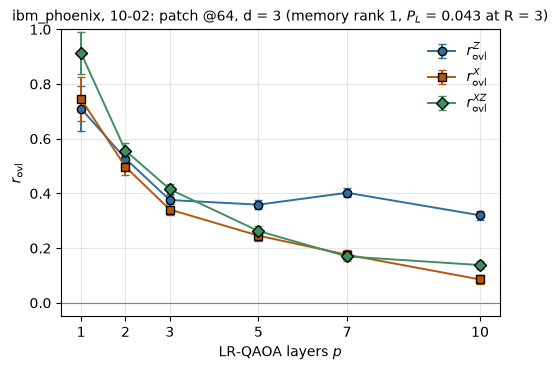

In [21]:
PATCH3 = None         # the patch to show, by its lowest data qubit (e.g. 64); None takes the one with the lowest P_L

best3 = (patches3[int(np.argmin(p_l))] if PATCH3 is None
         else next(q for q in patches3 if min(q.data_qubits) == PATCH3))
markers3 = {"Z": "o", "X": "s", "XZ": "D"}

fig, ax = plt.subplots(figsize=(5.2, 3.8))
for frame in frames3:
    by = frames3[frame][best3]
    ax.errorbar(depths3, [by[p]["r_ovl"] for p in depths3],
                yerr=[by[p]["r_err"] / (by[p]["r_ideal"] - by[p]["r_rand"]) for p in depths3],
                fmt=markers3[frame] + "-", color=colours3[frame], mec="black", ms=6, lw=1.4, capsize=3,
                label=rf"$r_{{\rm ovl}}^{{{frame}}}$")
    print(f"{frame:>2} frame: " + "  ".join(f"p={p}: {by[p]['r_ovl']:.3f}" for p in depths3))
i3 = patches3.index(best3)
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="LR-QAOA layers $p$", ylabel=r"$r_{\rm ovl}$", xticks=depths3, ylim=(-0.05, 1.0),
       title=f"{BACKEND}, {STAMP3[4:6]}-{STAMP3[6:8]}: patch @{min(best3.data_qubits)}, d = {DISTANCE3} "
             rf"(memory rank {int(truth3[i3])}, $P_L$ = {p_l[i3]:.3f} at R = {DEPTH3})")
ax.title.set_fontsize(10)
ax.grid(alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / f"{BACKEND}_best_patch_three_frames.pdf", bbox_inches="tight")
plt.show()